MCMC code to test whether the fitting of a schechter function is consistent with the sample of bursts </br>

Code from: https://philuttley.github.io/stats-methods-24/12-mcmc/index.html </br>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u
from matplotlib import rcParams
import matplotlib.gridspec as gridspec
import scipy.optimize as spopt
import numpy.ma as ma
import pandas as pd
from tqdm import tqdm
from matplotlib import transforms
import random
from scipy.optimize import curve_fit
from scipy.stats import chi2
from scipy.integrate import quad
import matplotlib.ticker as ticker
import powerlaw

In [2]:
import lmfit
from lmfit import Minimizer, Parameters, report_fit
import scipy.stats as sps
import emcee
import corner
import scipy.interpolate as spinterp
import scipy.integrate as spint

In [3]:
#In order to save the emcee progress
import h5py

In [33]:
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [6]:
def model_bin(xbins, model, params):
    '''General function for integrating the input model over bins defined by contiguous (no gaps) 
        bin edges, xbins.
       Inputs:
           xbins - x bin edges.
           model, params - the model name and associated Parameters object.
       Outputs:
           ymod - calculated counts-density model values for y-axis.'''
    i = 0
    ymod = np.zeros(len(xbins)-1)
    for i, xval in enumerate(xbins[:-1]):
        ymod[i], ymoderr = spint.quad(lambda x: model(x, params),xbins[i],xbins[i+1])
        ymod[i] = ymod[i]/(xbins[i+1]-xbins[i])  # we now divide by the bin width to match the counts density
        # units of our data
    return ymod

In [7]:
def LogLikelihood_Pois(model_counts, counts): 
    '''Calculate the negative Poisson log-likelihood for a model vs counts data. 
       Inputs:
           model_counts - array of predicted model counts per bin
           counts - data: observed counts per bin.
        Outputs: the negative Poisson log-likelihood'''
    pd = sps.poisson(model_counts) #we define our Poisson distribution
    return -1*np.sum(pd.logpmf(counts))

In [8]:
def lmf_poissll(params,xdata,ydata,model,output_ll=True):
    '''lmfit objective function to calculate and return total negative Poisson log-likelihood or model 
        y-values for binned data where the xdata are the contiguous (i.e. no gaps) input bin edges and 
        ydata are the counts (not count densities) per bin.
        Inputs: params - name of lmfit Parameters object set up for the fit.
                xdata, ydata - lists of 1-D arrays of x (must be bin edges not bin centres) 
                and y data and y-errors to be fitted.
                    E.g. for 2 data sets to be fitted simultaneously:
                        xdata = [x1,x2], ydata = [y1,y2], yerrs = [err1,err2], where x1, y1, err1
                        and x2, y2, err2 are the 'data', sets of 1-d arrays of length n1 (n1+1 for x2
                        since it is bin edges), n2 (n2+1 for x2) respectively, 
                        where n1 does not need to equal n2.
                    Note that a single data set should also be given via a list, i.e. xdata = [x1],...
                model - the name of the model function to be used (must take params as its input params and
                        return the model y counts density array for a given x-value array).
                output_resid - Boolean set to True if the lmfit objective function (total -ve 
                        log-likelihood) is required output, otherwise a list of model y-value arrays 
                        (corresponding to the input x-data list) is returned.
        Output: if output_resid==True, returns the total negative log-likelihood. If output_resid==False, 
                returns a list of y-model counts density arrays (one per input x-array)'''
    if output_ll == True:
        poissll = 0
        for i, xvals in enumerate(xdata):  # loop through each input dataset to sum negative log-likelihood
                # We can re-use our model binning function here, but the model then needs to be converted into 
                # counts units from counts density, by multiplying by the bin widths
                ymodel = model_bin(xdata[i],model,params)*np.diff(xdata[i])
                # Then obtain negative Poisson log-likelihood for data (in counts units) vs the model 
                poissll = poissll + LogLikelihood_Pois(ymodel,ydata[i])
        return poissll
    else:
        ymodel = []
        for i, xvals in enumerate(xdata): # record list of model y-value arrays, one per input dataset
            ymodel.append(model_bin(xdata[i],model,params))
        return ymodel

In [9]:
def fluence_limit(sefd=420, width=1, bw=100, snr=20):
    '''
    sefd in Jy, width in ms, bw in MHz
    '''
    fluence_limit = snr * sefd * np.sqrt( (width/1000.) / (2 * bw * 1e6))
    # return things in Jy~ms
    return fluence_limit * 1000

In [10]:
def iso_energ_to_fluence(energy, distance=362.4, redshift=0.0771):
    "Convert list of energy back to fluence"

    energy_arr = np.array(energy)
    
    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value

    #mpc to cm
    distance_lum_cm = megap_cm*distance
    
    #redshift correction, see evernote for details
    #redshift is from: Ravi et al, DSA-110
    #distance is also from Ravi et al, FAST converts themselves based on PLANCK 2016
    #link: https://ui.adsabs.harvard.edu/abs/2023ApJ...949L...3R/abstract
    z = redshift
    red_cor = 1 / (1 + z)**2

    fluences = (energy) / (4*np.pi*(distance_lum_cm**2) * 1e-23 * red_cor)
    #energy_iso = fluence_jys * 4*np.pi*(distance_lum_cm**2) * 1e-23 * red_cor
    #print(energy_iso)
    
    #convert from jyms to jys
    fluence_jys = fluences * 1e3
    
    return fluence_jys

In [11]:
def isotropic_energies(fluences, distance=362.4, redshift=0.0771):
    "Convert list of fluences to spectral densities"
    "Method based on fluence.py by K.Nimmo"

    #convert from jyms to jys
    fluence_jys = np.array(fluences) * 1e-3

    dis = 1.0 * u.megaparsec
    megap_cm = dis.to(u.cm).value

    #mpc to cm
    distance_lum_cm = megap_cm*distance
    
    #redshift correction, see evernote for details
    #redshift is from: Ravi et al, DSA-110
    #distance is also from Ravi et al, FAST converts themselves based on PLANCK 2016
    #link: https://ui.adsabs.harvard.edu/abs/2023ApJ...949L...3R/abstract
    z = redshift
    red_cor = 1 / (1 + z)**2

    energy_iso = fluence_jys * 4*np.pi*(distance_lum_cm**2) * 1e-23 * red_cor
    #print(energy_iso)

    return energy_iso

In [12]:
def fluences_arrays(df_fluences, telescope):
    "return Fluences arrays from different activity windows"

    #Westerbork
    fluences = df_fluences[df_fluences['telescope'] == telescope]
    fluences_arr = fluences['fluence'].values
    fluences_arr[::-1].sort()

    print(f'{telescope} : {len(fluences_arr)}')
    return fluences_arr

In [13]:
def toa_calulator(df):
    '''
    Return the toa of a burst
    in the case of multiple components of a single burst, take the middle of the burst
    '''
    if df.shape[0] == 1:
        mjd = df.iloc[0]["toa_bary_tdb_inf_freq"]

    elif df.shape[0] > 1:
        mjd_list = df["toa_bary_tdb_inf_freq"].values
        mjd = (mjd_list[0] + mjd_list[-1]) / 2
 
    return mjd

In [14]:
def fluence_looper(df_fluence):
    """
    function to sum over the fluences components of bursts
    returns the burst id and fluences in a pandas df
    
    Input: The burst_csv file with all information, spc/sfxc/scale
    This is needed because we return a df with fluence (spc) and toa (sfxc)
    """

    #the burst names to loop over
    exps = df_fluence['id'].unique()

    #Create a list with the telescope names for easy filtering later on
    exps_tel = [i.split('-')[1] for i in exps]

    #loop over every burst to sum the fluence
    info_list = []
    for exp, telescope in zip(exps, exps_tel):
        
        #Fluence: Making a small temp df for each exp, only taking the spc values
        if telescope != 'st':
            fluence_df_exp_temp = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'spc')]
            
            #TOA
            fluence_df_exp_temp_mjd = df_fluence[(df_fluence['id'] == exp) & (df_fluence['src'] == 'sfxc')]
            toa = toa_calulator(fluence_df_exp_temp_mjd) 
                
        elif telescope == 'st':
            fluence_df_exp_temp = df_fluence[df_fluence['id'] == exp]
            
            #TOA
            toa = toa_calulator(fluence_df_exp_temp) 
            
        #Calculate the total fluence
        fluence = sum(fluence_df_exp_temp['fluence_jyms'].values)
        
        #Since the F0 is the same for all components, take all components
        cent_freq = fluence_df_exp_temp['f0_MHz'].values[0]
                            
        #Add to the list
        info_list.append([fluence, cent_freq, toa])
        
    #Convert the fluence list to array
    info_list_arr = np.asarray(info_list)

    #Convert the info to dataframe
    new_data = {'id': exps, 'fluence': info_list_arr[:,0], 'telescope': exps_tel, 'c_freq':info_list_arr[:,1], 'toa': info_list_arr[:,2]}
    df_new_fluence = pd.DataFrame(data=new_data)

    #add only the index number as a seperate column for potential later use
    df_new_fluence['burst-index'] = df_new_fluence['id'].str.split('-').str[0].str[1:].astype(int)
    
    return df_new_fluence

In [15]:
def load_df(file, band, overlap_wb_st=False, mjd_limit=False):
    """
    Function to load in the burst.csv file and return the Fluences per burst
    
    band: specifiy wether Lband or Pband bursts
    mjd_limit: use the MJD_range or use all bursts in the dataset
    
    notes:
    B84  is missing, since it was determined to not be real after classification
    B130 is actively removed from calculations, since the RFI made it impossible to measure properties
    """

    #load in the main csv file
    fluence_df = pd.read_csv(file, index_col=0)
    fluence_df.sort_values(by=['id'])
    
    # Specifically remove B130-tr
    mask = fluence_df['id'] == 'B130-tr'
    fluence_df = fluence_df[~mask]

    ##Wb, On and Tr Fluences
    #Only take the spc fluences
    #df_spc = fluence_df[fluence_df['src'] == 'spc']
    df_combined = fluence_looper(fluence_df)    
    df_combined.sort_values(by=['id'])
           
    #Dropping the duplicate bursts:    
    #In case there is overlap with Torun, drop Torun due to bad baseline
    #In case St/Wb overlap, drop the fainter burst
    #29-Aug-23 double checked the overlaps
    tr_overlap = ["B07-tr","B13-tr","B15-tr","B16-tr","B37-tr"]
    
    if overlap_wb_st == True:
        st_overlap = ["B30-st","B53-st","B63-st","B64-st","B68-st","B69-st","B104-st","B107-st"]
        wb_overlap = ["B82-wb","B85-wb","B106-wb"]
    else:
        st_overlap = []
        wb_overlap = []

    #Dropping the overlap bursts
    overlaps = np.concatenate((tr_overlap, st_overlap, wb_overlap))
    df_combined = df_combined[~df_combined['id'].isin(overlaps)]
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        df_combined = df_combined[df_combined['toa'].between(mjd_begin, mjd_end)]
        
    #Filter based on observing frequency    
    if band == "L":
        df_combined = df_combined[df_combined['c_freq'] != 328]
    elif band == "P":
        df_combined = df_combined[df_combined['c_freq'] == 328]
        
    #Resort and reset the df
    df_combined = df_combined.sort_values(by=['burst-index'])
    df_combined = df_combined.reset_index(drop=True)
    
    #display(df_combined)
    return df_combined

In [16]:
def nancay_r117(csv_file, mjd_limit=True):
    """
    Read in the .csv Nancay file with values for Nancay bursts
    reference: David
    host: private repo from David shared with Ould-Boukattine
    
    return: a df with toa,fluence and central frequency
    """
    
    nancay_df = pd.read_csv(csv_file, na_values='NA')

    #Filter only on real bursts, according to David
    nancay_df_real = nancay_df[nancay_df["Real Burst"] == True]

    bw = np.mean(nancay_df_real['freq width'].values*4)
    width = np.mean(nancay_df_real['time width'].values*1.6e-2)
    #print(f"bandwidth = {bw}, width = {width}")
    
    #Make a MJD column for easy filtering
    #print(nancay_df_real["cand name"].str.split("_", expand=True)[2], nancay_df_real["cand name"].str.split("_", expand=True)[4])
    
    #Create mjd_start and tcand columns from the "cand name" string column
    #print(nancay_df_real["cand name"].str.split("_").str[2].astype(float))
    nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
    
    nancay_df_real["tcand"] = nancay_df_real["cand name"].str.split("_").str[4].astype(float)
    
    #Createa a detection FETCH MJD column for easy reference later on
    nancay_df_real["toa"] = nancay_df_real["mjd_start"] + (nancay_df_real["tcand"] / (24*3600))
    nancay_df_real["telescope"] = "nc"
    
    nancay_df_real_subset = nancay_df_real[["toa", 'fluence', "center frequency", 'cand name', 'telescope']]
    
    nancay_df_real_subset = nancay_df_real_subset.sort_values(by=['toa'])
    nancay_df_real_subset = nancay_df_real_subset.reset_index(drop=True)
    
    if mjd_limit ==True:
        mjd_begin = 59869
        mjd_end = 59910
        nancay_df_real_subset = nancay_df_real_subset[nancay_df_real_subset['toa'].between(mjd_begin, mjd_end)]
        
#     print(nancay_df_real.columns)
#     display(nancay_df_real_subset)
    
    return nancay_df_real_subset

nancay_fluence_r117 = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
                                 mjd_limit=True)

/tmp/ipykernel_2543781/1048473980.py:10: DtypeWarning: Columns (14,15,16,26) have mixed types. Specify dtype option on import or set low_memory=False.
  nancay_df = pd.read_csv(csv_file, na_values='NA')
/tmp/ipykernel_2543781/1048473980.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
/tmp/ipykernel_2543781/1048473980.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["tcand"] = nancay_df_real[

In [17]:
def fast_r117(csv_file):
    """
    Read in csv FAST .csv file  
    from: https://ui.adsabs.harvard.edu/abs/2023arXiv230414665Z/abstract
    host: https://www.scidb.cn/en/detail?dataSetId=18a982901dd244f6b236bab445095e57
    """
    
    col = ['MJD','DM','DMError','Flux','FluxError','Width','PeakFrequency',\
             'PeakFrequencyError','BandWidth','BandWidthError','Fluence','FluenceError','Energy',\
             'RM','RMErrorLeft','RMErrorRight','Linear','LinearError','Circular','CircularError']
    fast_csv = pd.read_csv(csv_file, sep=",", skiprows=2, header=None, index_col=0, na_values='NA', names=col)
    
    mjd_begin = 59869
    mjd_end = 59910
    fast_csv = fast_csv[fast_csv['MJD'].between(mjd_begin, mjd_end)]
    fluence=fast_csv['Fluence'].values
    
    return fluence

In [18]:
def global_fit_calc(threshold_modifier=1.0):
    """
    Function that will combine and return the energies

    No duplicate bursts are taken into account -- we filter those out before fitting
    
    Overlap between Stockert and the ATA with Fluences 
    ATA did not have overlap except with Stockert
    B40-st 145 -  5-ATA 168
    B41-st  32 -  6-ATA 224
    B60-st 504 - 15-ATA 281
    B93-st 420 - 25-ATA 1129
    B98-st 662 - 26-ATA 625

    drop:
    B40-st, B41-st, B93-st
    15-ATA, 26-ATA
    
    Our campaign: 59867 -- 59983
    ATA campaign: 59872 -- 59933
    NRT campaign: 59880 -- 59935
    
    For the plot we only consider detections between 59867 -- 59935
    Between 59933 and 59983 we had only 3 L-band detections in ~50 days. 

    Important:
    All information is beforehand calculated and saved in a .csv file to be imported at a later stage
    name of the csv file: mcmc_energy_info.csv
    """
    #Initiate empty dict
    pandas_dict = {}
    
    #Importing the Fluences for small dishes
    fluence_df = load_df("../../dbs/burst_stats_r117.csv", band="L", overlap_wb_st=True, mjd_limit=False)
    
    #Import Nancay fluences, 
    #Setting mjd_limit False, to get the entire campaign
    df_nancay_fluence_r117 = nancay_r117(csv_file="/home/omar/git/nancay-r117/Burst-analyis-R117-Nancay/fixed_fluences.csv",\
                                 mjd_limit=False)
    nancay_fluences = df_nancay_fluence_r117['fluence'].values

    #Import FAST fluences
    fast_fluence_r117 = fast_r117(csv_file="../../dbs/FRB20220912A-Table.csv")
    
    #Burst that fall outside the overlap with the ATA/nancay, these are only 3 bursts -- bursts detected after 59933
    burst_exclude = ["B129-st", "B131-st", "B132-tr"]
    fluence_df = fluence_df[~fluence_df['id'].isin(burst_exclude)]

    #Duplicate stockert bursts that are fainter than the ATA observed bursts
    burst_exclude = ["B40-st", "B41-st", "B93-st"]
    fluence_df = fluence_df[~fluence_df['id'].isin(burst_exclude)]
    
    fluences_stk_arr = fluences_arrays(fluence_df, telescope='st')
    fluences_wb_arr = fluences_arrays(fluence_df, telescope='wb')
    fluences_tr_arr = fluences_arrays(fluence_df, telescope='tr')

    #Importing the Fluence for the ATA from my own made csv-file
    csv_file="../../dbs/allen-telescope/R117_allen_omar.csv"
    df_allen = pd.read_csv(csv_file, index_col=0)  
    
    #The ATA bursts that have overlap with Stockert and are fainter are dropped
    at_overlap = [15,26]
    df_allen = df_allen[~df_allen['id'].isin(at_overlap)]
    allen_fluences = df_allen['fluence'].values
    
    #Converting to energies
    energies_wb = isotropic_energies(fluences_wb_arr)
    energies_st = isotropic_energies(fluences_stk_arr)
    energies_tr = isotropic_energies(fluences_tr_arr)
    energies_at = isotropic_energies(allen_fluences)
    energies_nc = isotropic_energies(nancay_fluences)
    energies_fs = isotropic_energies(fast_fluence_r117)
    
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15)
    #energie_threshold_wb = isotropic_energies([f_limit_wb])
    print(f"threshold wb: {f_limit_wb:.2f} jy ms")
    
    f_limit_stk = fluence_limit(sefd=385, width=3, bw=90, snr=15)
    #energie_threshold_st = isotropic_energies([f_limit_stk])
    print(f"threshold st: {f_limit_stk:.2f} jy ms")
    
    f_limit_tr = fluence_limit(sefd=250, width=3, bw=100, snr=15)
    #energie_threshold_tr = isotropic_energies([f_limit_tr])
    print(f"threshold tr: {f_limit_tr:.2f} jy ms")

    #4.7 jy ms for a burst at 10 sigma, multiple by 1.5 for a 15 sigma equivalent.
    f_limit_at = 4.7*1.5
    print(f"threshold at: {f_limit_at:.2f} jy ms")
    #energie_threshold_at = isotropic_energies([f_limit_at])

    #Nancay/FAST is not in this array, since it's always more sensitive
    threshold_arr = np.array([f_limit_wb, f_limit_stk, f_limit_tr, f_limit_at])
    max_threshold_fl = np.max(threshold_arr) * threshold_modifier
    print(f"The max threshold used is:{max_threshold_fl:.2f} Jy ms")
    
    max_threshold_arr = isotropic_energies([max_threshold_fl])

    energies_wb_limit = energies_wb[energies_wb > max_threshold_arr]
    energies_tr_limit = energies_tr[energies_tr > max_threshold_arr]
    energies_st_limit = energies_st[energies_st > max_threshold_arr]
    energies_at_limit = energies_at[energies_at > max_threshold_arr]
    energies_nc_limit = energies_nc[energies_nc > max_threshold_arr]
    energies_fs_limit = energies_fs[energies_fs > max_threshold_arr]
    
    print(f"lenght of arr - wb:{len(energies_wb_limit)}, tr:{len(energies_tr_limit)},st:{len(energies_st_limit)}, at:{len(energies_at_limit)}, nc:{len(energies_nc_limit)},fs:{len(energies_fs_limit)}")

    #All info for doing a global fit on the fluences
    energies_global = np.concatenate([energies_wb_limit, energies_tr_limit, energies_st_limit, energies_at_limit, energies_nc_limit,energies_fs_limit])
    energies_global.sort()

    pandas_dict['threshold_jy_ms'] = max_threshold_fl
    pandas_dict['threshold_erg_hz'] = max_threshold_arr
    pandas_dict['treshold_factor'] = threshold_modifier
    pandas_dict['N_bursts'] = len(energies_global)
    pandas_dict['N_wb'] = len(energies_wb_limit)
    pandas_dict['N_stk'] = len(energies_st_limit)
    pandas_dict['N_tr'] = len(energies_tr_limit)
    pandas_dict['N_nc'] = len(energies_nc_limit)
    pandas_dict['N_ata'] = len(energies_at_limit)
    pandas_dict['N_fs'] = len(energies_fs_limit)

    ##Create the name template for the emcee run and the energy run, that will be used for the h5 file
    name = f'output_treshold_{threshold_modifier}'
    pandas_dict['base_name'] = name

    #we save the name of the array and use savetext following this stackoverflow
    #https://stackoverflow.com/questions/28439701/how-to-save-and-load-numpy-array-data-properly
    name_energies = name + "_energies.txt"
    pandas_dict['energy_arr_erg_hz_name'] = name_energies
    np.savetxt(name_energies, energies_global)
    
    ## Create a pandas dataframe for this threshold
    df_dummy = pd.DataFrame(pandas_dict, index=[0])

    #Load the main csv with info
    #mcmc_csv_name = 'mcmc_energy_info.csv'
    mcmc_csv_name = 'mcmc_energy_info_logprior_var.csv'
    csv_obs_pd = pd.read_csv(mcmc_csv_name, sep=",", header=0, index_col=0, na_values='NA', engine='python')

    #Concatenate the two pandas dataframes
    df_combined = pd.concat([csv_obs_pd, df_dummy],ignore_index=True)

    #Dropping the duplicate lines from the combined df // makes sure to keep the last run :) 
    #Sort on treshold_jy_ms in combination with N_bursts
    df_combined = df_combined.drop_duplicates(subset=['threshold_jy_ms', 'N_bursts'], keep='last', ignore_index=True)
    
    display(df_combined)
    df_combined.to_csv(mcmc_csv_name, sep=",", header=True, index=True, na_rep='NA')
    
    return 

In [19]:
def func_schechter(x, params):
    '''Power-law function with an exponential cut-off.
       Inputs:
           x - input x value(s) (can be list or single value).
           parm - parameters, list of PL normalisation (at x = 1) and power-law index.'''
    v = params.valuesdict()
    return v['N'] *((x/v['E_cut'])**v['gamma']) * np.exp(-x/v['E_cut'])

In [20]:
def func_schechter_emcee(x, pars):
    '''Power-law function with an exponential cut-off.
       Inputs:
           x - input x value(s) (can be list or single value).
           pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
    (N,gamma,E_cut) = pars
    return N *((x/E_cut)**gamma)*np.exp(-x/E_cut)

In [21]:
def func_powerlaw_emcee(x, pars):
    '''Power-law function 
       Inputs:
           x - input x value(s) (can be list or single value).
           pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
    (N,gamma) = pars
    return N *((x)**gamma)

In [22]:
def plot_spec_model(ebins,cdens,cdens_err,cdens_model):
    '''Plot the binned (GeV) spectrum with the model as a histogram, and 
       data/model residuals.
       Inputs:
           ebins - energy bin edges.
           cdens, cdens_err - counts density and its error.
           cdens_model - model counts density.'''
    energies = (ebins[1:]+ebins[:-1])/2
    bwidths = np.diff(ebins)
    fig, (ax1, ax2) = plt.subplots(2,1, figsize=(8,6),sharex=True,gridspec_kw={'height_ratios':[2,1]})
    fig.subplots_adjust(hspace=0)
    ax1.errorbar(energies, cdens, xerr=bwidths/2., yerr=cdens_err, fmt='o')
    model_hist, edges, patches = ax1.hist(energies, bins=ebins, weights=cdens_model, 
                                      density=False, histtype='step')
    ax2.errorbar(energies, cdens/cdens_model, xerr=bwidths/2., yerr=cdens_err/cdens_model, fmt='o')
    ax2.set_xlabel("Spectral energy density (erg/Hz)", fontsize=16)
    ax1.set_ylabel("Counts/erg/Hz", fontsize=14)
    ax2.set_ylabel("data/model", fontsize=14)
    ax2.axhline(1.0, color='r', linestyle='dotted', lw=2) 
    ax1.tick_params(labelsize=14)
    ax1.tick_params(axis="x",direction="in",which="both", length=4)
    ax2.tick_params(axis="x",which="both", length=4)
    ax2.tick_params(labelsize=14)
    ax1.set_yscale('log')
    ax1.set_xscale('log')
    ax2.set_xscale('log')
    #ax1.get_yaxis().set_label_coords(-0.12,0.5)
    #ax2.get_yaxis().set_label_coords(-0.12,0.5)
    ax2.set_xlim(ebins[0],ebins[-1]) # Strictly speaking we should only show the energy range 
    # where data is sampled, to avoid impression from model that the flux suddenly drops 
    # at the boundaries.
    plt.show()

In [23]:
from multiprocess import Pool

def plexp_logprior(pars):
    '''returns the combined log-prior for the given input pars. Here we assume a uniform
    within specified limits, and zero probability (-ve infinity log-p) otherwise.
    
    comment: 29-Jan
    In the example, cut_off was set to max energy of 20, while true value was 4.
    In the Schechter function it is ~2, so 20 should also work.
    '''
    (N,gamma,E_cut) = pars
    if ((E_cut <= 0.5) | (E_cut >= 50)):
        return -np.inf
    #if ((E_cut <= 0) | (E_cut >= 1000)):
    else:
        return 0

In [24]:
def lmf_poissll_emcee(params,xdata,ydata,model,prior_model,output_ll=True):
    '''lmfit-style objective function to calculate and return total Poisson log-likelihood or model 
        y-values for binned data where the xdata are the contiguous (i.e. no gaps) input bin edges and 
        ydata are the counts (not count densities) per bin.
        Inputs: params - name of lmfit Parameters object set up for the fit.
                xdata, ydata - lists of 1-D arrays of x (must be bin edges not bin centres) 
                and y data and y-errors to be fitted.
                    E.g. for 2 data sets to be fitted simultaneously:
                        xdata = [x1,x2], ydata = [y1,y2], yerrs = [err1,err2], where x1, y1, err1
                        and x2, y2, err2 are the 'data', sets of 1-d arrays of length n1 (n1+1 for x2
                        since it is bin edges), n2 (n2+1 for x2) respectively, 
                        where n1 does not need to equal n2.
                    Note that a single data set should also be given via a list, i.e. xdata = [x1],...
                model - the name of the model function to be used (must take params as its input params and
                        return the model y counts density array for a given x-value array).
                output_resid - Boolean set to True if the lmfit objective function (total -ve 
                        log-likelihood) is required output, otherwise a list of model y-value arrays 
                        (corresponding to the input x-data list) is returned.
        Output: if output_resid==True, returns the total negative log-likelihood. If output_resid==False, 
                returns a list of y-model counts density arrays (one per input x-array)'''
    if output_ll == True:
        poissll = 0
        for i, xvals in enumerate(xdata):  # loop through each input dataset to sum negative log-likelihood
                # We can re-use our model binning function here, but the model then needs to be converted into 
                # counts units from counts density, by multiplying by the bin widths
                ymodel = model_bin(xdata[i],model,params)*np.diff(xdata[i])
                # Then obtain negative Poisson log-likelihood for data (in counts units) vs the model 
                poissll = poissll + (-1*LogLikelihood_Pois(ymodel,ydata[i]))
        poissll_prior = poissll + prior_model(params)     
        if not np.isfinite(poissll_prior):
            return -np.inf
        else:
            return poissll_prior
    else:
        ymodel = []
        for i, xvals in enumerate(xdata): # record list of model y-value arrays, one per input dataset
            ymodel.append(model_bin(xdata[i],model,params))
        return ymodel

In [25]:
def run_emcee(treshold_factor=1.0, nbins=20, steps=1000):

    ###############
    #Loading in the .csv file with the information
    #Load the main csv with info
    #csv_name = 'mcmc_energy_info.csv'
    #csv_name = 'mcmc_energy_info_25bin.csv'
    csv_name = 'mcmc_energy_info_logprior_var.csv'
    energy_info_file = pd.read_csv(csv_name, sep=",", header=0, index_col=0, na_values='NA', engine='python')

    #Retrieving the energies from the .txt file
    energies_file = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['energy_arr_erg_hz_name'].values[0]
    energies = np.loadtxt(energies_file)
    print(f"running the MCMC with: {len(energies)} bursts for treshold_factor: {treshold_factor}")

    #Retrieving the emcee save_name format
    #Placing a specific value in a df, from: https://stackoverflow.com/questions/28439701/how-to-save-and-load-numpy-array-data-properly
    #Apologies for the variable and columns name to be the same, it is what it is :) 
    base_name = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['base_name'].values[0]
    emcee_name = 'emcee_' + base_name + f'_{nbins}bins' + f'_{steps}steps.h5'
    energy_info_file.loc[energy_info_file.treshold_factor == treshold_factor, "emcee_name"] = emcee_name

    display(energy_info_file)
    energy_info_file.to_csv(csv_name, sep=",", header=True, index=True, na_rep='NA')
    
    ###############
    #Binning the data, devide by 1e32 
    # counts, edges = np.histogram(energies/1e32, bins=nbins, density=False)

    #Get it to log-bins // where 20 is the same amount of bins used for the MCMC run. Apples to Apples1.
    bin_num = nbins
    bins = np.logspace(np.log10(np.min(energies/1e32)), np.log10(np.max(energies/1e32)), bin_num)
    counts, edges = np.histogram(energies/1e32, bins=bins, density=False) ###
    
    bwidths = np.diff(edges) # calculates the width of each bin
    cdens = counts/bwidths # determines the count densities
    cdens_err = np.sqrt(counts)/bwidths # calculate the errors: remember the error is based on the counts, 
    # not the count density, so we have to also apply the same normalisation.
    energies = (edges[:-1]+edges[1:])/2.  # This calculates the energy bin centres
   
    params = Parameters()
    #name, value, vary, min, max
    params.add_many(('N',20),('gamma',-1),('E_cut',1))
    model = func_schechter
    output_ll = True
    xdata = [edges]
    ydata = [counts]

    print(params, xdata, ydata)
    set_function = Minimizer(lmf_poissll, params, fcn_args=(xdata, ydata, model, output_ll), 
                             nan_policy='omit',calc_covar=True)
    result = set_function.scalar_minimize(method='Nelder-Mead') # We specify the method for completeness, 
                                                                # but Nelder-Mead is the default
    print(result.x)
    report_fit(result)
    print("Summed log-likelihood = ",-1*result.residual)

    # To calculate the best-fitting model values, use the parameters of the best fit output
    # from the fit, result.params and set output_resid=false to output a list of model y-values:
    model_vals = lmf_poissll(result.params,xdata,ydata,model,output_ll=False)
    # Now plot the data and model and residuals. model_vals contains a list of model y-value arrays, here there is only one but we should still identify its index. 
    plot_spec_model(edges,cdens,cdens_err,model_vals[0]) 
    print(model_vals[0])
    
    ###############
    #Creating the best parameters list
    best_par_list = []
    for par in ['N','gamma','E_cut']:
        best_par_list.append(result.params[par].value)
    best_par=np.array(best_par_list) # needs to be an array so we can use it for calculations
    ndim, nwalkers = 3, 100  # The number of parameters and the number of walkers (we follow the 
    # emcee example and use 100)
    output_ll=True
    pos = [best_par + 0.01*best_par*sps.norm.rvs(size=ndim) for i in range(nwalkers)]  # we spread the 
    # walkers around the MLEs with a standard deviation equal to 1 per cent of the MLE value

    ###############
    #Running the Emcee code
    model = func_schechter_emcee
    prior_model = plexp_logprior

    ##Method to save the output of the emcee code 
    location = "/data1/omar/r117-paper-h5-files/prior_var/"
    backend = emcee.backends.HDFBackend(location+emcee_name)

    sampler = emcee.EnsembleSampler(nwalkers, ndim, lmf_poissll_emcee, 
                                    args=(xdata,ydata,model,prior_model,output_ll),pool=Pool(),backend=backend)
    sampler.run_mcmc(pos, steps, progress=True)

    # save_name = f'plexp_samplerchain_{steps}steps_{nbins}bins_test_sleipnir'
    # np.save(save_name,sampler.chain)

    return 

In [26]:
def calc_chi2_values(x, y, yerr, func, params):
    """
    Parameters
    ----------
    x : 1d numpy array
        The independent variable where the data is measured.
    y : 1d numpy array
        The dependent data, same shape as x.
    yerr : 1d numpy array
        values of the standard deviations of errors in y.
    func : function
        The function/model for which you want to calculate.
    params : 1d numpy array or python list
        parameter values for the model.

    Returns
    -------
    chi2 : float
        chi-squared value.
    redchi2 : float
        reduced chi-squared value.

    """

    # calculate the model values
    ymodel = func(x, params)
    # calculate the chi-squared values
    chi2 = np.sum(((y - ymodel) / yerr)**2.0)
    # determine degrees of freedom
    dof = x.shape[0] - params.shape[0]
    # calculate the reduced chi-squared value
    redchi2 = chi2 / dof
    
    return chi2, redchi2

In [27]:
# #!!!Dont run again!!!!
def make_pandas_df():
    """
    Create empty array to append later, only have to run once.
    code run: 27-May-24 -- please don't run again :) Cheers

    Made a 15bin version on 13Dec 24, with name: mcmc_energy_info_15bin.csv and 25bin.csv
    """
    
    df = pd.DataFrame(columns=['threshold_jy_ms','threshold_erg_hz','treshold_factor','N_bursts','N_wb','N_stk','N_tr',\
                               'N_nc','N_ata', 'N_fs','energy_arr_erg_hz_name','base_name'])
    #df.to_csv("mcmc_energy_info.csv")
    #df.to_csv("mcmc_energy_info_25bin.csv")
    df.to_csv("mcmc_energy_info_logprior_var.csv")
    
#make_pandas_df()
# #!!!Dont run again!!!!

# Running the code

## Part 1 
First we calculate the energy arrays for different Fluence thresholds </br>

- Standard Fluence limit = 24.40 Jy ms of Westerbork
    - This number is determined on 15sigma, 3ms detection on 100 MHz detection
    - Number of bursts: 125
- 0.66 x fluence limit at 16.10 Jy ms
    - Number of bursts: 146
- 1.33 x fluence limit at 32.45 Jy ms
    - Number of bursts: 112

All information for the prep for the emcee run is then saved in a pandas_csv file for easy insight and reproduction </br>
We save: threshold/#bursts/#bursts_per_telescope/energy_arr_save_name

DONE: array made on 27-May-2024 | In principle this is not to be touched anymore!

## Part 2
Then we can run the MCMC analysis based on these different arrays. 

- Load the csv file with the information and run the MCMC code 3 times for all threshold_modifiers
- All MCMC is run with 100 walkers at 10_000 (10K) steps

## Part 3
Based on the energy arrays and the saved .h5-MCMC files we can make the plots

In [28]:
##Breakpoint from Nancay determined with the two powerlaws ; calculated as a Fluence and then taken as the 
def min_energy_nrt():
    breakpoint_fluence = iso_energ_to_fluence(energy=3.2270117582755933e+30, distance=362.4, redshift=0.0771)
    f_limit_wb = fluence_limit(sefd=420, width=3, bw=100, snr=15) 
    ratio = breakpoint_fluence/f_limit_wb
    print(f"treshold modifier - nrt = {ratio:.3f}")
    return
min_energy_nrt()

treshold modifier - nrt = 0.976


In [29]:
fluence_limit(sefd=385, width=3, bw=90, snr=15)

23.576338774288086

In [30]:
# def min_energy_wb():
#     """
#     This is the fluence limit from Wb, as shown in the cumulative distribution
#     """
#     f_limit_wb = fluence_limit(sefd=385, width=3, bw=90, snr=15)
    
#     energy_wb = isotropic_energies(fluences=f_limit_wb, distance=362.4, redshift=0.0771)
#     print(energy_wb)
#     breakpoint_fluence_wb = iso_energ_to_fluence(energy=energy_wb, distance=362.4, redshift=0.0771)
    
#     print(f"treshold modifier - wb = {breakpoint_fluence_wb/13.044395:.3f}")

#     return
# min_energy_wb()

In [31]:
#Code run on 27-May
def csv_fac_filler():

    #The run in the paper
    #factors = [0.66,0.976,1.0,1.33,2.0,2.5,3.0]

    #15 bin run and the 25 bin run
    factors = [1.0]
    for fac in factors:
        global_fit_calc(threshold_modifier=fac)

    return
csv_fac_filler()

st : 72
wb : 31
tr : 5
threshold wb: 24.40 jy ms
threshold st: 23.58 jy ms
threshold tr: 14.52 jy ms
threshold at: 7.05 jy ms
The max threshold used is:24.40 Jy ms
lenght of arr - wb:22, tr:2,st:62, at:29, nc:8,fs:2


/tmp/ipykernel_3795094/1048473980.py:10: DtypeWarning: Columns (14,15,16,26) have mixed types. Specify dtype option on import or set low_memory=False.
  nancay_df = pd.read_csv(csv_file, na_values='NA')
/tmp/ipykernel_3795094/1048473980.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["mjd_start"] = nancay_df_real["cand name"].str.split("_").str[2].astype(float)
/tmp/ipykernel_3795094/1048473980.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nancay_df_real["tcand"] = nancay_df_real[

,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name
0,24.399795,3.304924e+30,1.0,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0


running the MCMC with: 125 bursts for treshold_factor: 1.0


/tmp/ipykernel_3795094/4109647963.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'emcee_output_treshold_1.0_20bins_10000steps.h5' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  energy_info_file.loc[energy_info_file.treshold_factor == treshold_factor, "emcee_name"] = emcee_name


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name
0,24.399795,3.304924e+30,1.0,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_20bins_10000steps.h5


Parameters([('N', <Parameter 'N', value=20, bounds=[-inf:inf]>), ('gamma', <Parameter 'gamma', value=-1, bounds=[-inf:inf]>), ('E_cut', <Parameter 'E_cut', value=1, bounds=[-inf:inf]>)]) [array([0.03556783, 0.04413812, 0.05477347, 0.06797147, 0.08434961,
       0.10467416, 0.12989603, 0.16119527, 0.20003625, 0.24823621,
       0.30805023, 0.38227681, 0.47438873, 0.58869558, 0.73054537,
       0.90657472, 1.12501941, 1.39609969, 1.7324984 , 2.14995444])] [array([12, 12,  7,  9,  4, 13,  6, 10,  6,  3,  6,  6,  6,  7,  6,  3,  3,
        4,  1])]
[11.08939606 -1.16649454  2.2333837 ]
[[Fit Statistics]]
    # fitting method   = Nelder-Mead
    # function evals   = 264
    # data points      = 1
    # variables        = 3
    chi-square         = 1691.98284
    reduced chi-square = 1691.98284
    Akaike info crit   = 13.4336564
    Bayesian info crit = 7.43365640
##  Warning: uncertainties could not be estimated:
    this fitting method does not natively calculate uncertainties
    and num

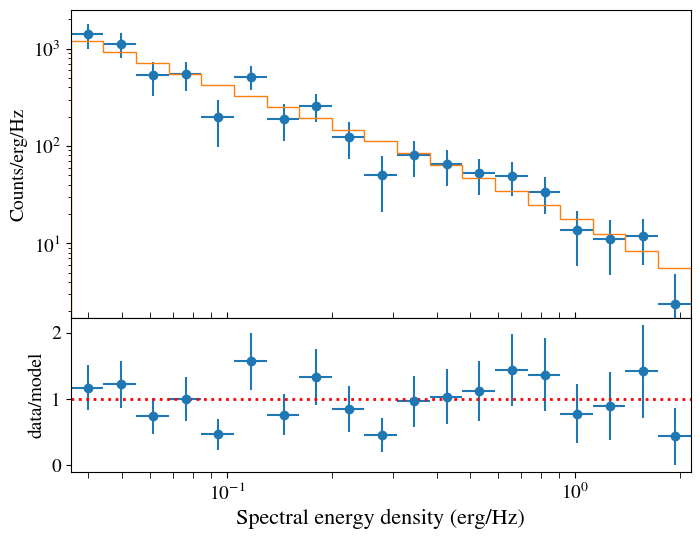

[1199.3283572   928.35268697  717.86050248  554.38490443  427.45769794
  328.94189611  252.51282592  193.2547505   147.34728486  111.82160454
   84.37089398   63.20293721   46.92543833   34.45674632   24.95628215
   17.77023389   12.38908209    8.41431314    5.53232791]


  0%|▋                                                                                                                                                                                                           | 32/10000 [00:03<18:25,  9.02it/s]/tmp/ipykernel_3795094/4254691771.py:7: RuntimeWarning: invalid value encountered in scalar power
  return N *((x/E_cut)**gamma)*np.exp(-x/E_cut)
/tmp/ipykernel_3795094/1597742055.py:12: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  ymod[i], ymoderr = spint.quad(lambda x: model(x, params),xbins[i],xbins[i+1])
  0%|▋                                                                                                                                                                                                           | 35/10000 [00:04<19:25,  8.55it/s]/tmp/ipykernel_3795094/4254691771.py:7: RuntimeWarning: invalid value encounter

In [32]:
# #Running the MCMC analysis 7 times for different thresholds. 
def emcee_hammer():
    """
    function to loop over the factors and call the emcee
    isnt it a great function name? 
    """

    #0.2 was done on May29
    #factors = [0.66,0.976,1.0,1.33,2.0,2.5,3.0]

    #15 bin run and the 25 bin run
    factors = [1.0]
    
    for fac in factors:
        run_emcee(treshold_factor=fac, nbins=20, steps=10000)

    return

emcee_hammer()

In [31]:
def chi_sqrt_normal_bins(energies_global, med_values, nbins=20):

    energies = energies_global/1e32
    
    N=med_values[0]
    gamma=med_values[1]
    ecut=med_values[2]
    
    counts, edges = np.histogram(energies, bins=nbins, density=False)
    energies = (edges[1:]+edges[:-1])/2

    bwidths = np.diff(edges) # calculates the width of each bin
    print(bwidths)
    cdens = counts/bwidths # determines the count densities
    cdens_err = np.sqrt(counts)/bwidths # calculate the errors: remember the error is based on the counts,

    ##Residuals
    y_model = func_schechter_emcee(energies, [N, gamma, ecut])

    #Find out where the frac is zero
    ratio = cdens/y_model

    #Mask to delete the zero values in the plot
    mask = (ratio != 0)
    
    #Chi2 calculation:
    chi2, chi2red = calc_chi2_values(x=energies[mask], y=cdens[mask], yerr=cdens_err[mask], \
                                     func=func_schechter_emcee, params=np.array([N, gamma, ecut]))    

    print(f"chi2: {chi2:.2f} and redchi2 {chi2red:.2f}")
    return chi2, chi2red

In [105]:
#run_emcee(treshold_factor=0.66, nbins=20, steps=10000)

In [106]:
# ndim, nsamples = 4, 50000
# np.random.seed(1234)
# data1 = np.random.randn(ndim * 4 * nsamples // 5).reshape(
#     [4 * nsamples // 5, ndim]
# )
# mean = 4 * np.random.rand(ndim)
# value1 = mean

# print(value1[None])

In [35]:
def draw_figure(treshold_factor=1.5):

    """
    filename_emcee = filename given to the h5 file
    subfigure exp. it out on this page: https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subfigures.html
    """

    ###############
    #Loading in the .csv file with the information
    #Load the main csv with info
    energy_info_file = pd.read_csv('mcmc_energy_info.csv', sep=",", header=0, index_col=0, na_values='NA', engine='python')

    #Load in the file name of the emcee run to load the sampler
    filename_emcee = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['emcee_name'].values[0]

    #Retrieving the energies from the .txt file
    energies_file = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['energy_arr_erg_hz_name'].values[0]
    energies_global = np.loadtxt(energies_file)
    print(f"loading up the energies with len: {len(energies_global)} bursts for treshold_factor: {treshold_factor}")
    
    fig = plt.figure(figsize=(20,10))
    subfig1, subfig2 = fig.subfigures(ncols=2)

    #############################################################################
    ############## Corner Plot ##############
    #############################################################################

    location = "/data1/omar/r117-paper-h5-files/"
    sampler = emcee.backends.HDFBackend(location + filename_emcee)

    #Discard -- for the burn in
    discard_samp = 500
    
    flat_samples_full = sampler.get_chain(discard=discard_samp, flat=True)
    print("Median and 1-sigma errors")
    #Changed this to hardcoded, since we won't change the function anymore
    ndim=3

    #This code is getting even dirtier, I need to save the error on e_char, but that is the last one calculated.
    #So q[0] and q[1] are the e_char errors in the order of the for loop, which I will use for the right hand plot.
    #Sorry for future users.
    med_values = []
    for i in range(ndim):
        mcmc = np.percentile(flat_samples_full[:, i], [15.85, 50, 84.15])
        q = np.diff(mcmc)
        txt = "{3} = {0:.3f} -{1:.3f}/+ {2:.3f}" # This formatting rounds to 3 decimal places.
        txt = txt.format(mcmc[1], q[0], q[1], ['N','Gamma','E_char'][i])
        print(txt)
        med_values.append(mcmc[1])

    #The error on e_char is stored in q[0] and q[1]
    print(q[0], q[1])
    
    labels_list = [r'$N$',r'$\gamma_{\rm{D}}$',r'$E_{\rm{char},32}$'] # labels for our plots
    flat_samples = sampler.get_chain(discard=discard_samp, thin=30, flat=True) 

    fig_corn = corner.corner(flat_samples, labels=labels_list, smooth=0.5, \
                        max_n_ticks=5, show_titles=True, color="#d95f02",\
                        fill_contours=False, title_kwargs={"fontsize": 26},linewidth=30, truths=med_values, truth_color="#7570b3",\
                        plot_datapoints=True, range=[(-22, 230), (-1.6, -0.4), (-2.5, 27)],\
                        hist_kwargs={"linewidth":3}, label_kwargs={"fontsize": 26},\
                        fig=subfig1)

    #Setting up custom plotting of the truth lines
    corner.overplot_lines(fig_corn, med_values, color="#7570b3", lw=2.5)
    
    #Hacky tacky method to get label ticks larger size -- from: https://github.com/dfm/corner.py/issues/102
    for ax in fig_corn.get_axes():
        ax.tick_params(axis='both', labelsize=17)

        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(1.5)

            ax.tick_params(axis='y', which='major', direction='out', length=5, width=1.5)
            ax.tick_params(axis='x', which='major', direction='out', length=5, width=1.5)

    #############################################################################
    ############## Data Plot ##############
    #############################################################################

    #Best fit parameters on the model
    print(med_values)
    N=med_values[0]
    gamma=med_values[1]
    ecut=med_values[2]

    energies = energies_global/1e32
    
    ax1, ax2 = subfig2.subplots(2,1,sharex=True,gridspec_kw={'height_ratios':[2,0.6]})
    subfig2.subplots_adjust(hspace=0)

    #Get it to log-bins // where 20 is the same amount of bins used for the MCMC run. Apples to Apples1.
    bin_num = 20
    bins = np.logspace(np.log10(np.min(energies)), np.log10(np.max(energies)), bin_num)

    counts, edges = np.histogram(energies, bins=bins, density=False) ###
    energies = (edges[1:]+edges[:-1])/2

    bwidths = np.diff(edges) # calculates the width of each bin
    cdens = counts/bwidths # determines the count densities
    cdens_err = np.sqrt(counts)/bwidths # calculate the errors: remember the error is based on the counts, 

    ax1.bar(energies, cdens, width=bwidths, align='center',edgecolor = 'purple', alpha=0.25,color='purple', linewidth=1.1)
    ax1.bar(energies, cdens, width=bwidths, align='center',edgecolor = 'purple', alpha=1.0,color='None', linewidth=1.1)
    ax1.errorbar(energies, cdens, xerr=bwidths/2., yerr=cdens_err, fmt='o', color="purple")
    ax1.axvline(ecut, color='#d95f02', alpha=0.8, linestyle="--", \
                label=fr"$E_{{\rm char}}={ecut:.2f}\times 10^{{32}}$ erg Hz$^{{-1}}$")
    neg_error = q[0]
    pos_error = q[1]
    ax1.axvspan(ecut - neg_error, ecut + pos_error, alpha=0.1, color='#d95f02')
    ax1.axvspan(ecut - neg_error, ecut + pos_error, alpha=1.0, color='None',ec='#d95f02', linestyle='-', linewidth=1.05)
    
    pars=[N, gamma, ecut]
    x_range = np.linspace(0.9*edges[0], edges[-1]*3.5, 800)
    y = func_schechter_emcee(x_range, [N, gamma, ecut])
    y_p = func_powerlaw_emcee(x_range, [N*2.21,gamma])

    # if treshold_factor == 1.0:
    #     ax1.plot(x_range,y_p, color='black', label="Powerlaw Function", lw=2.5, ls='dashed',alpha=0.8)
        
    ax1.plot(x_range,y, color='#1b9e77', label="Schechter Function", lw=3.5)
    ax1.set_xlim(0.7*edges[0], 7)
    ax1.set_ylim(0.95,20000)    

    ##Residuals
    y_model = func_schechter_emcee(energies, [N, gamma, ecut])
    ax2.set_ylim(0,2.2)
    ax2.axhline(1, linestyle="-.", color="black", lw=2)

    #Find out where the frac is zero
    ratio = cdens/y_model

    #Mask to delete the zero values in the plot
    mask = (ratio != 0)
    ax2.errorbar(energies[mask], ratio[mask], xerr=bwidths[mask]/2., yerr=cdens_err[mask]/y_model[mask], fmt='o', color='purple')

    for ax in [ax1,ax2]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
        
        ax.tick_params(axis='both', which='major', labelsize=27)

    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_ylabel(fr"Count density", fontsize=28)
    ax2.set_ylabel(fr"Data/model", fontsize=28, labelpad=28)
    ax2.set_xlabel(r"Spectral energy density (erg Hz$^{-1}$)", fontsize=28)    
    
    ax1.legend(loc='upper left', fontsize=19, markerscale=2)

    #This is extremly dirty, please forgive me for my sins (although it's still accurate in terms of science)
    #https://stackoverflow.com/questions/11244514/modify-tick-label-text
    #We get the labels, replace it with the 32 power x-axis and adjust it
    labels = [item.get_text() for item in ax2.get_xticklabels()]
    print('x-axis labels:',labels)
    labels = [l.replace('$\\mathdefault{10^{-1}}$', '$\\mathdefault{10^{31}}$') for l in labels]
    labels = [l.replace('$\\mathdefault{10^{0}}$', '$\\mathdefault{10^{32}}$') for l in labels]
    print('x-axis labels:',labels)
    ax2.set_xticklabels(labels)
    
    #############################################################################
    ############## Chi2 calculations ##############
    #############################################################################
    
    #Chi2 calculation:
    chi2, chi2red = chi_sqrt_normal_bins(energies_global, med_values, bin_num)
    
    # chi2, chi2red = calc_chi2_values(x=energies[mask], y=cdens[mask], yerr=cdens_err[mask], \
    #                                  func=func_schechter_emcee, params=np.array([N, gamma, ecut]))
    #print(f"chi2: {chi2:.2f} and redchi2 {chi2red:.2f}")

    energy_info_file.loc[energy_info_file.treshold_factor == treshold_factor, "chi2"] = chi2
    energy_info_file.loc[energy_info_file.treshold_factor == treshold_factor, "redchi2"] = chi2red
    display(energy_info_file)
    
    energy_info_file.to_csv('mcmc_energy_info.csv', sep=",", header=True, index=True, na_rep='NA')
    
    #############################################################################
    ############## Saving Plot ##############
    #############################################################################

    save_name_base = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['base_name'].values[0]
    save_name="MCMC_plot_" + save_name_base + f"_{bin_num}bins" + "_V3" 
    print(save_name)
    plt.savefig(f"{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    plt.savefig(f"{save_name}.png", \
            bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()
        
    return 

loading up the energies with len: 125 bursts for treshold_factor: 1.0
Median and 1-sigma errors
N = 13.521 -10.941/+ 32.999
Gamma = -1.118 -0.132/+ 0.172
E_char = 2.086 -1.045/+ 3.822
1.0448310867699007 3.8220616664865155
[13.5207842422809, -1.1175429863920847, 2.086054205358285]
x-axis labels: ['$\\mathdefault{10^{-3}}$', '$\\mathdefault{10^{-2}}$', '$\\mathdefault{10^{-1}}$', '$\\mathdefault{10^{0}}$', '$\\mathdefault{10^{1}}$', '$\\mathdefault{10^{2}}$']
x-axis labels: ['$\\mathdefault{10^{-3}}$', '$\\mathdefault{10^{-2}}$', '$\\mathdefault{10^{31}}$', '$\\mathdefault{10^{32}}$', '$\\mathdefault{10^{1}}$', '$\\mathdefault{10^{2}}$']
[0.10571933 0.10571933 0.10571933 0.10571933 0.10571933 0.10571933
 0.10571933 0.10571933 0.10571933 0.10571933 0.10571933 0.10571933
 0.10571933 0.10571933 0.10571933 0.10571933 0.10571933 0.10571933
 0.10571933 0.10571933]
chi2: 9.34 and redchi2 0.78


/tmp/ipykernel_2543781/4016923930.py:164: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels)


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_1.0_20bins_V3


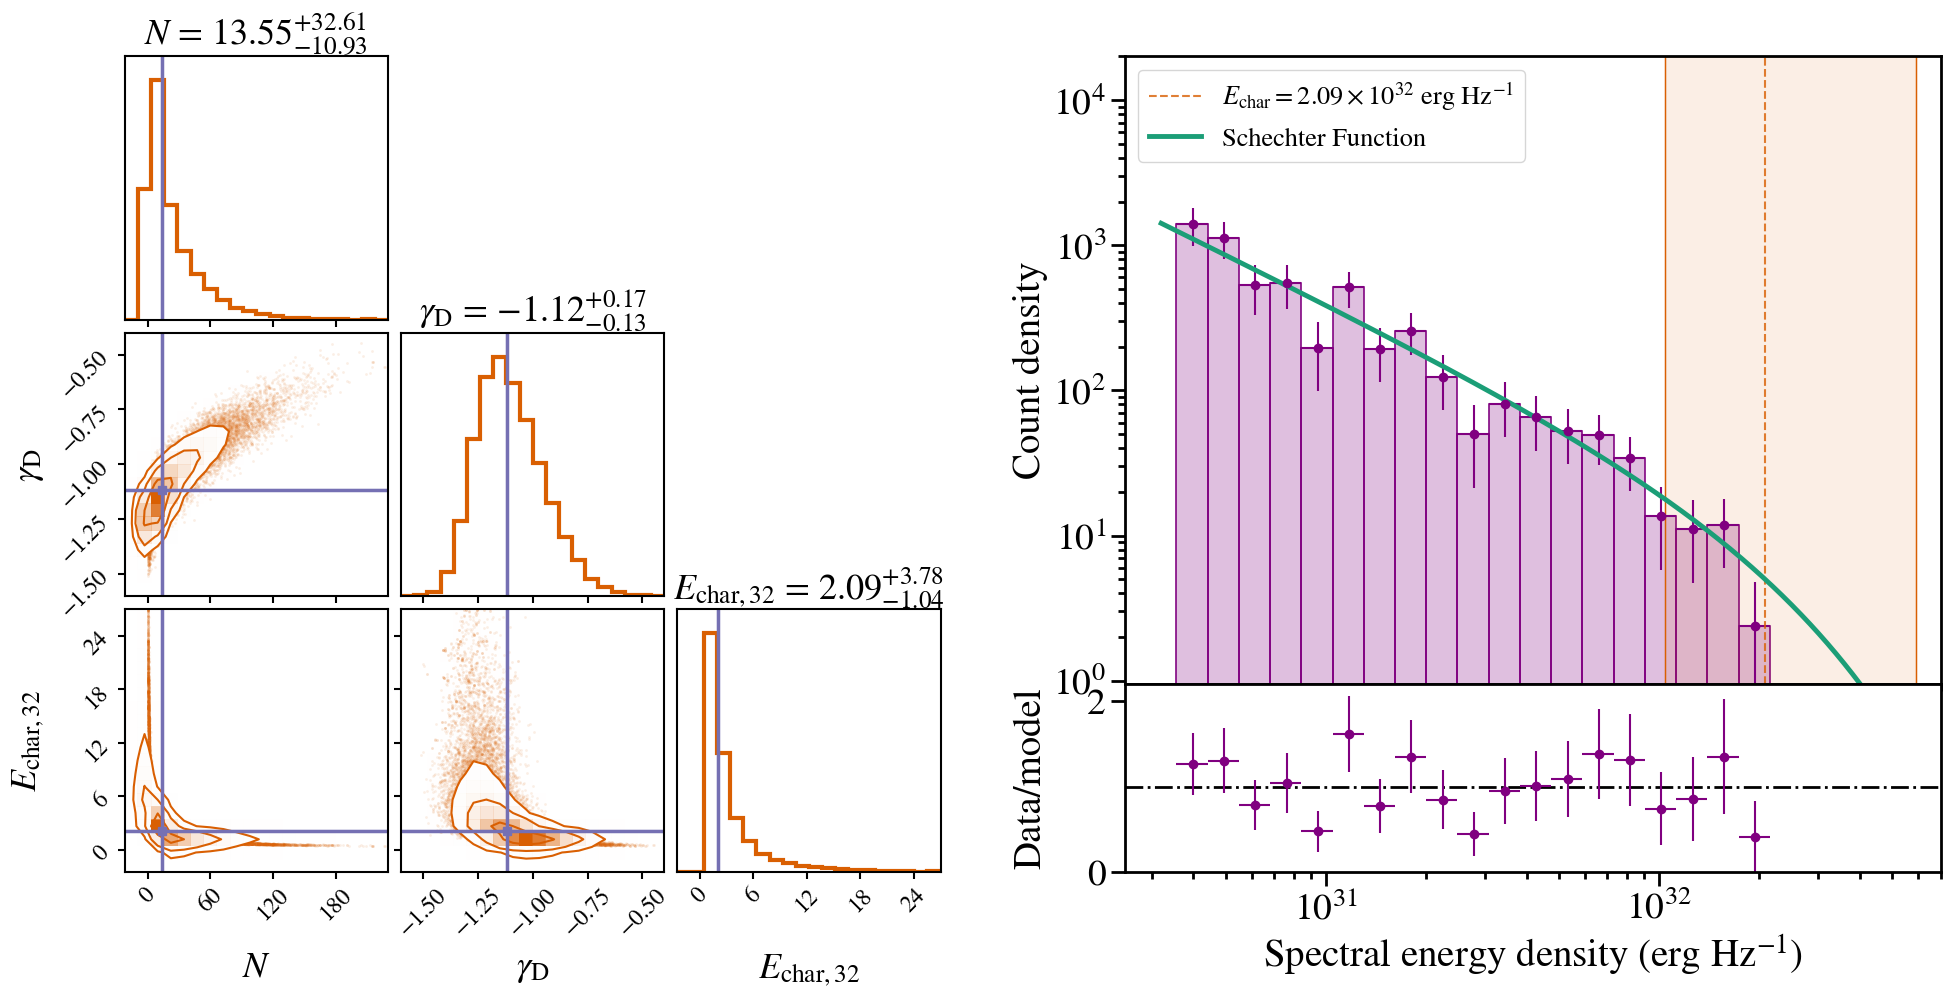

In [36]:
draw_figure(treshold_factor=1.0)

In [30]:
def log_prob(treshold_factor=1.0):
    
    ###############
    #Loading in the .csv file with the information
    #Load the main csv with info
    energy_info_file = pd.read_csv('mcmc_energy_info.csv', sep=",", header=0, index_col=0, na_values='NA', engine='python')

    #Load in the file name of the emcee run to load the sampler
    filename_emcee = energy_info_file[energy_info_file['treshold_factor'] == treshold_factor]['emcee_name'].values[0]
    
    location = "/data1/omar/r117-paper-h5-files/"
    sampler = emcee.backends.HDFBackend(location + filename_emcee)

    #Discard -- for the burn in
    discard_samp = 500
    
    flat_samples_full = sampler.get_chain(discard=discard_samp, flat=True)
    
    log_probs = sampler.get_log_prob(flat=True,discard=discard_samp)
    print(np.max(log_probs))

    k = 3
    N = 20 
    L = np.max(log_probs)
    BIC = k * np.log(N) - 2*L
    print(BIC)
    
    return
log_prob()

-33.531942194404266
76.05108120947051


loading up the energies with len: 146 bursts for treshold_factor: 0.66
Median and 1-sigma errors
N = 9.717 -8.351/+ 24.991
Gamma = -1.144 -0.105/+ 0.139
E_cut = 2.532 -1.331/+ 6.930
1.3308832002784763 6.930291985581607
[9.716952603582744, -1.144254294228236, 2.532246047881464]
chi2: 13.51 and redchi2 1.13


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_0.66


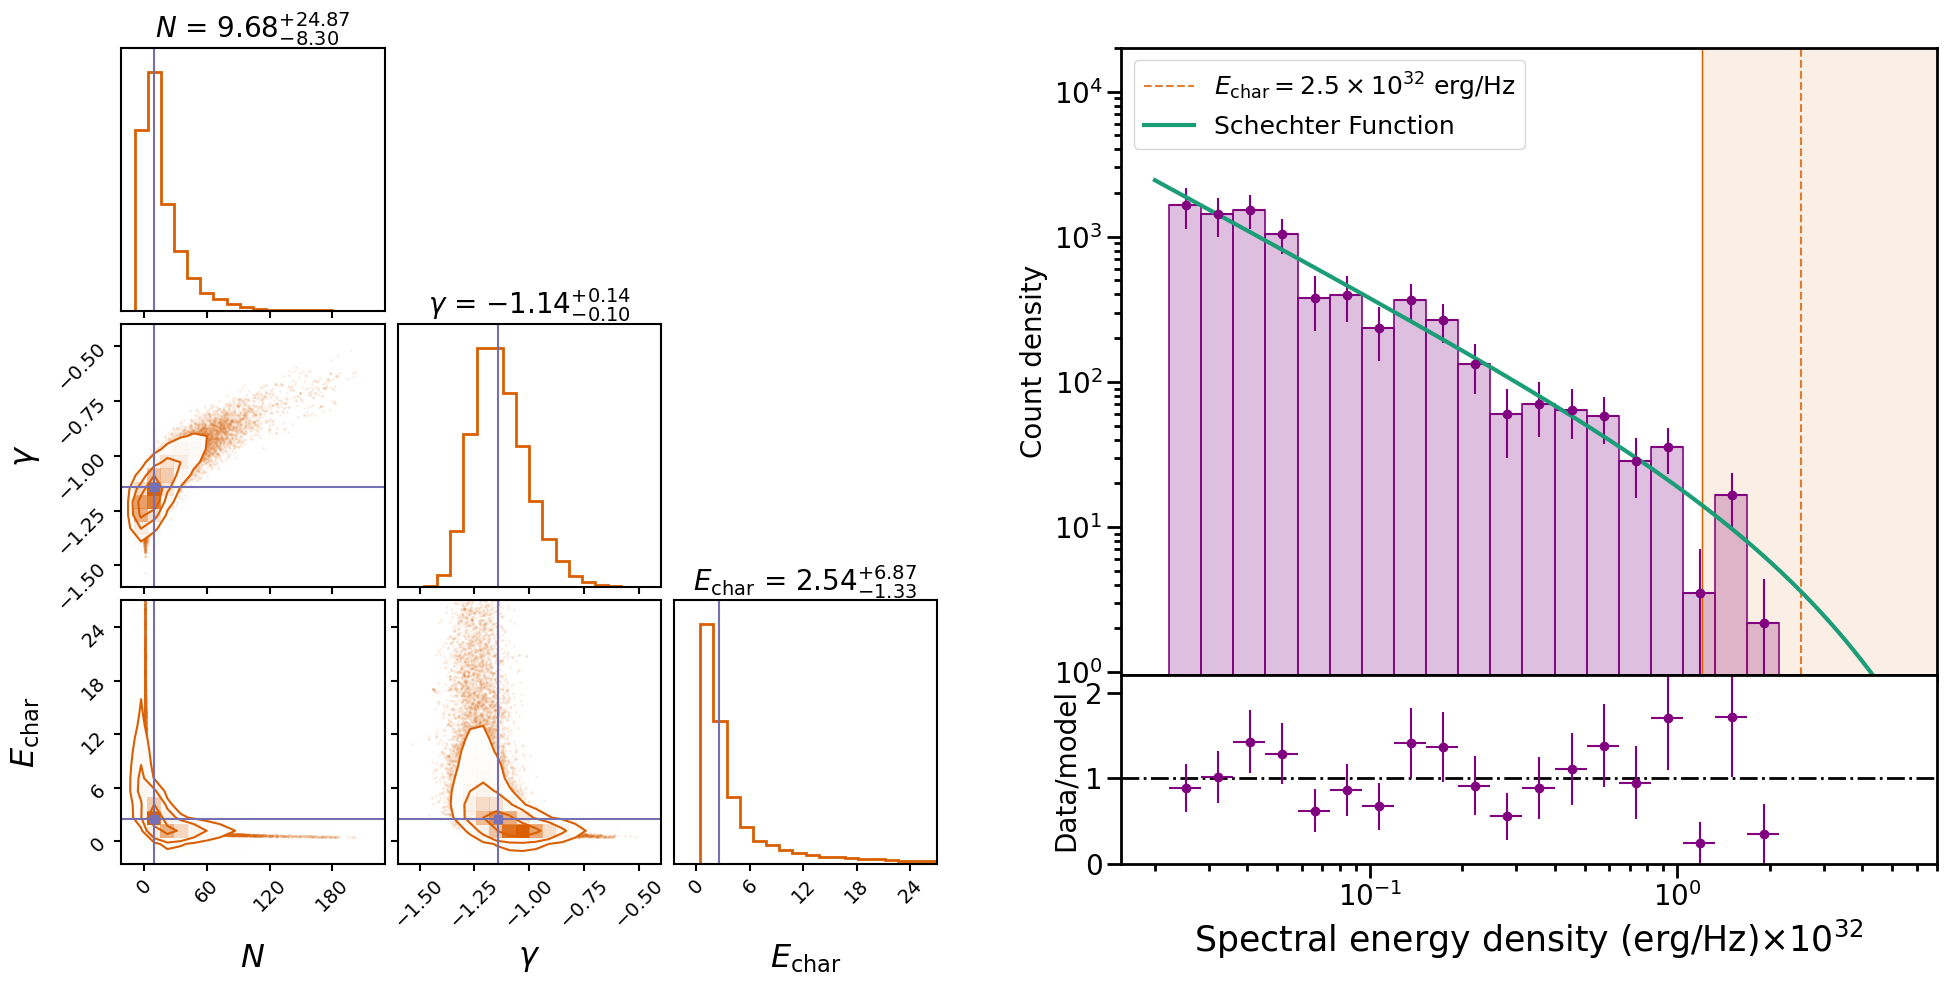

loading up the energies with len: 130 bursts for treshold_factor: 0.976
Median and 1-sigma errors
N = 12.417 -10.143/+ 28.857
Gamma = -1.135 -0.121/+ 0.159
E_cut = 2.165 -1.067/+ 4.266
1.0674276427159537 4.266145796576349
[12.416740689194878, -1.1345101536102775, 2.165350783299407]
chi2: 10.25 and redchi2 0.85


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_0.976


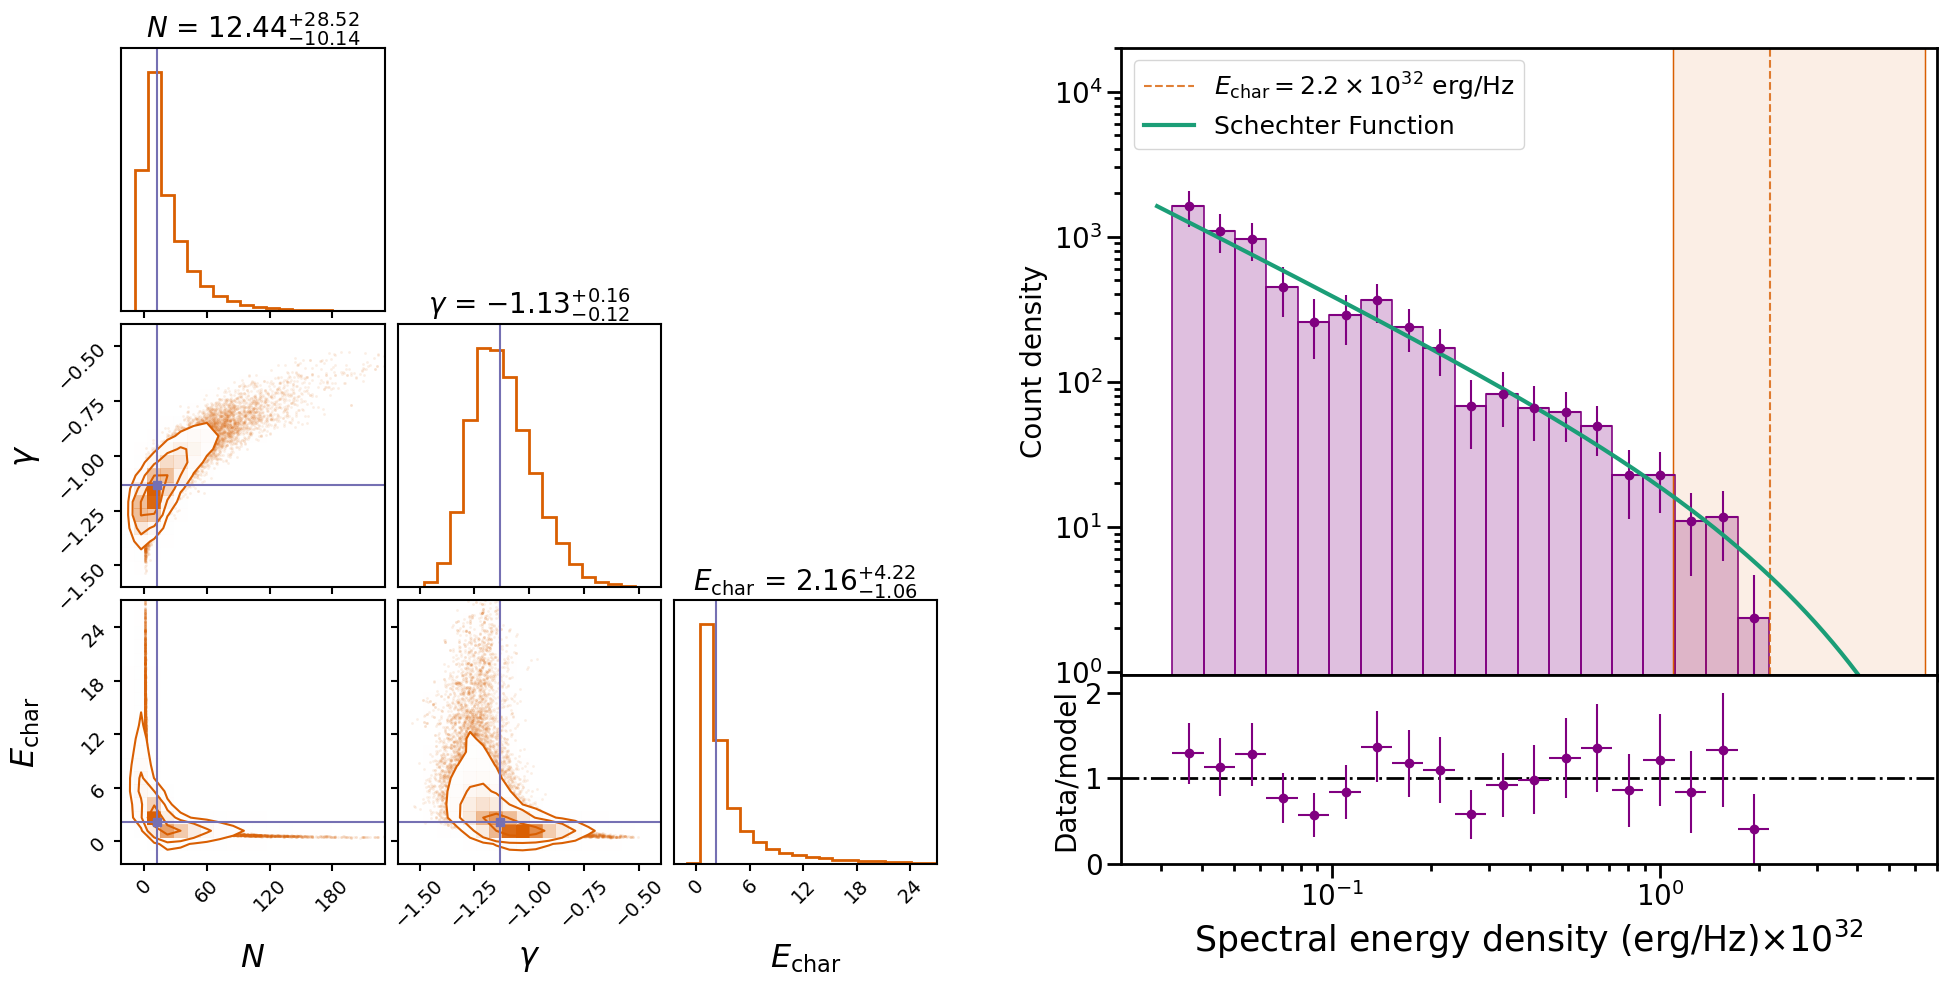

loading up the energies with len: 125 bursts for treshold_factor: 1.0
Median and 1-sigma errors
N = 13.521 -10.941/+ 32.999
Gamma = -1.118 -0.132/+ 0.172
E_cut = 2.086 -1.045/+ 3.822
1.0448310867699007 3.8220616664865155
[13.5207842422809, -1.1175429863920847, 2.086054205358285]
chi2: 9.34 and redchi2 0.78


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_1.0


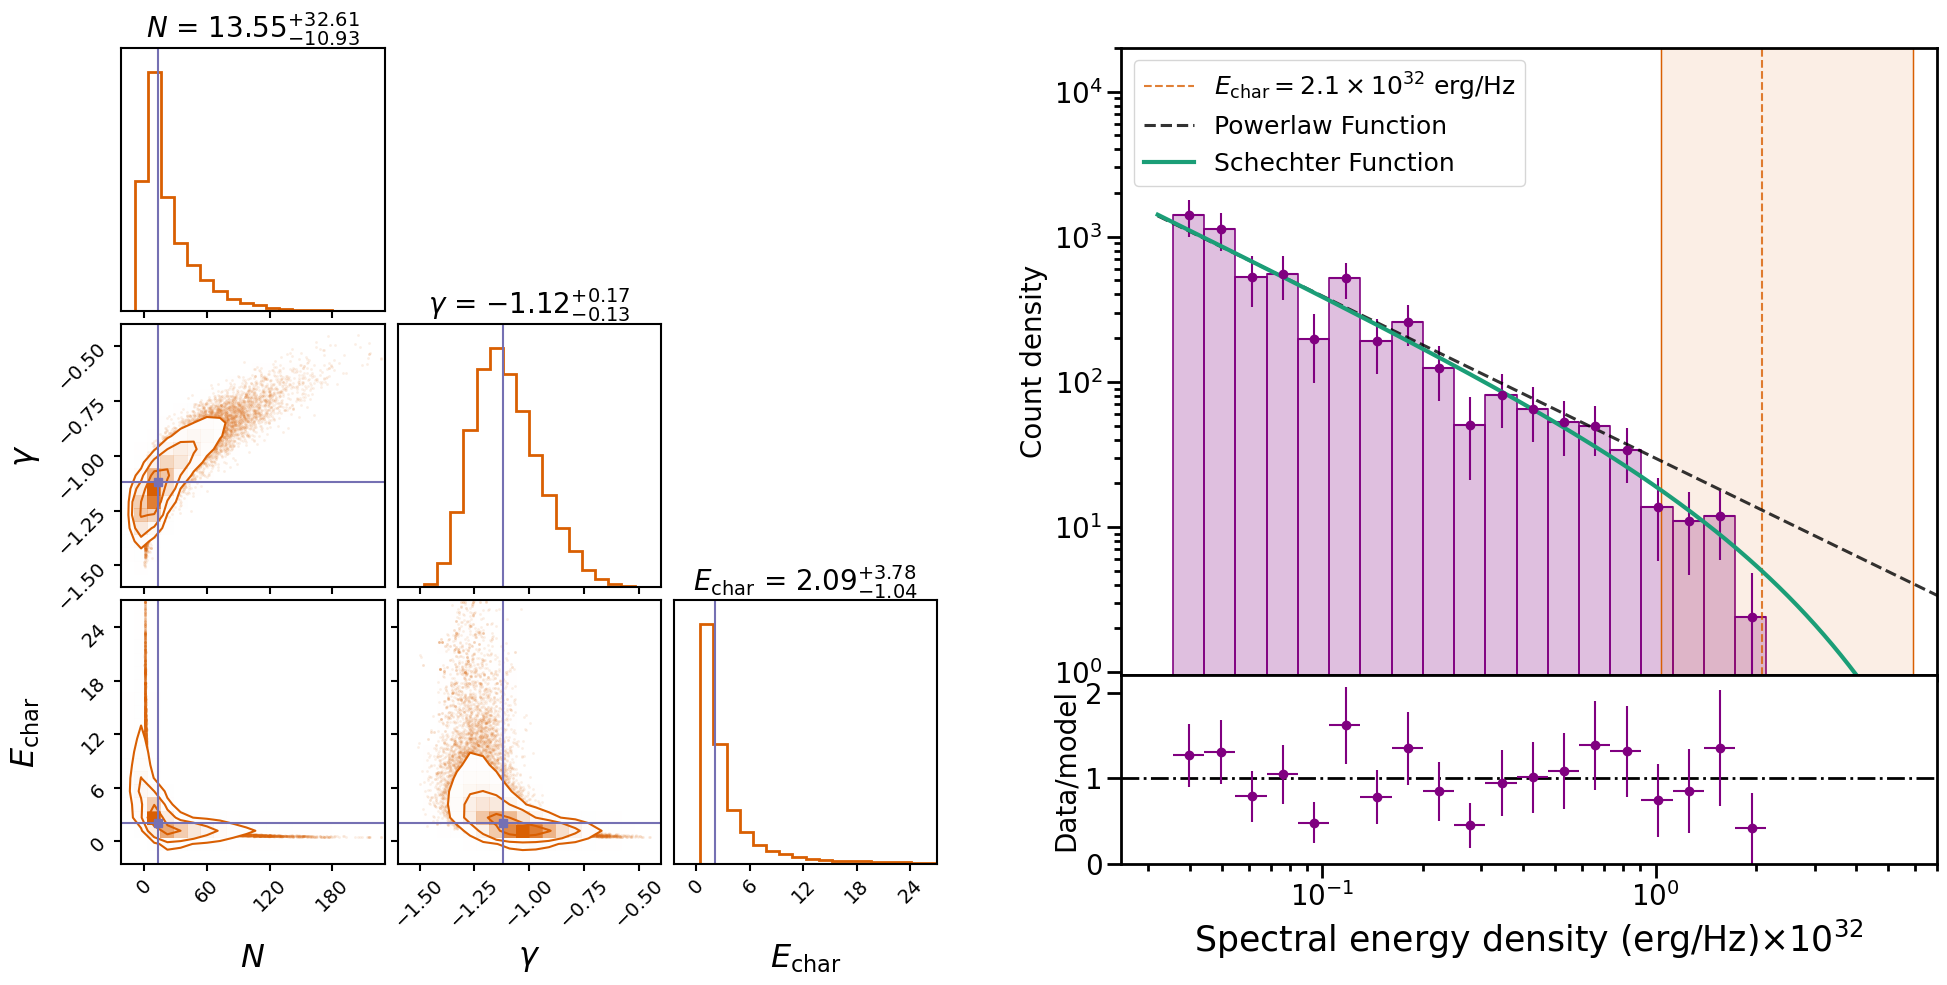

loading up the energies with len: 112 bursts for treshold_factor: 1.33
Median and 1-sigma errors
N = 20.327 -16.103/+ 40.699
Gamma = -1.051 -0.150/+ 0.199
E_cut = 1.677 -0.764/+ 2.729
0.763965836217721 2.7291851148377493
[20.3269187522991, -1.051435304079964, 1.6772996160014833]
chi2: 7.97 and redchi2 0.66


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_1.33


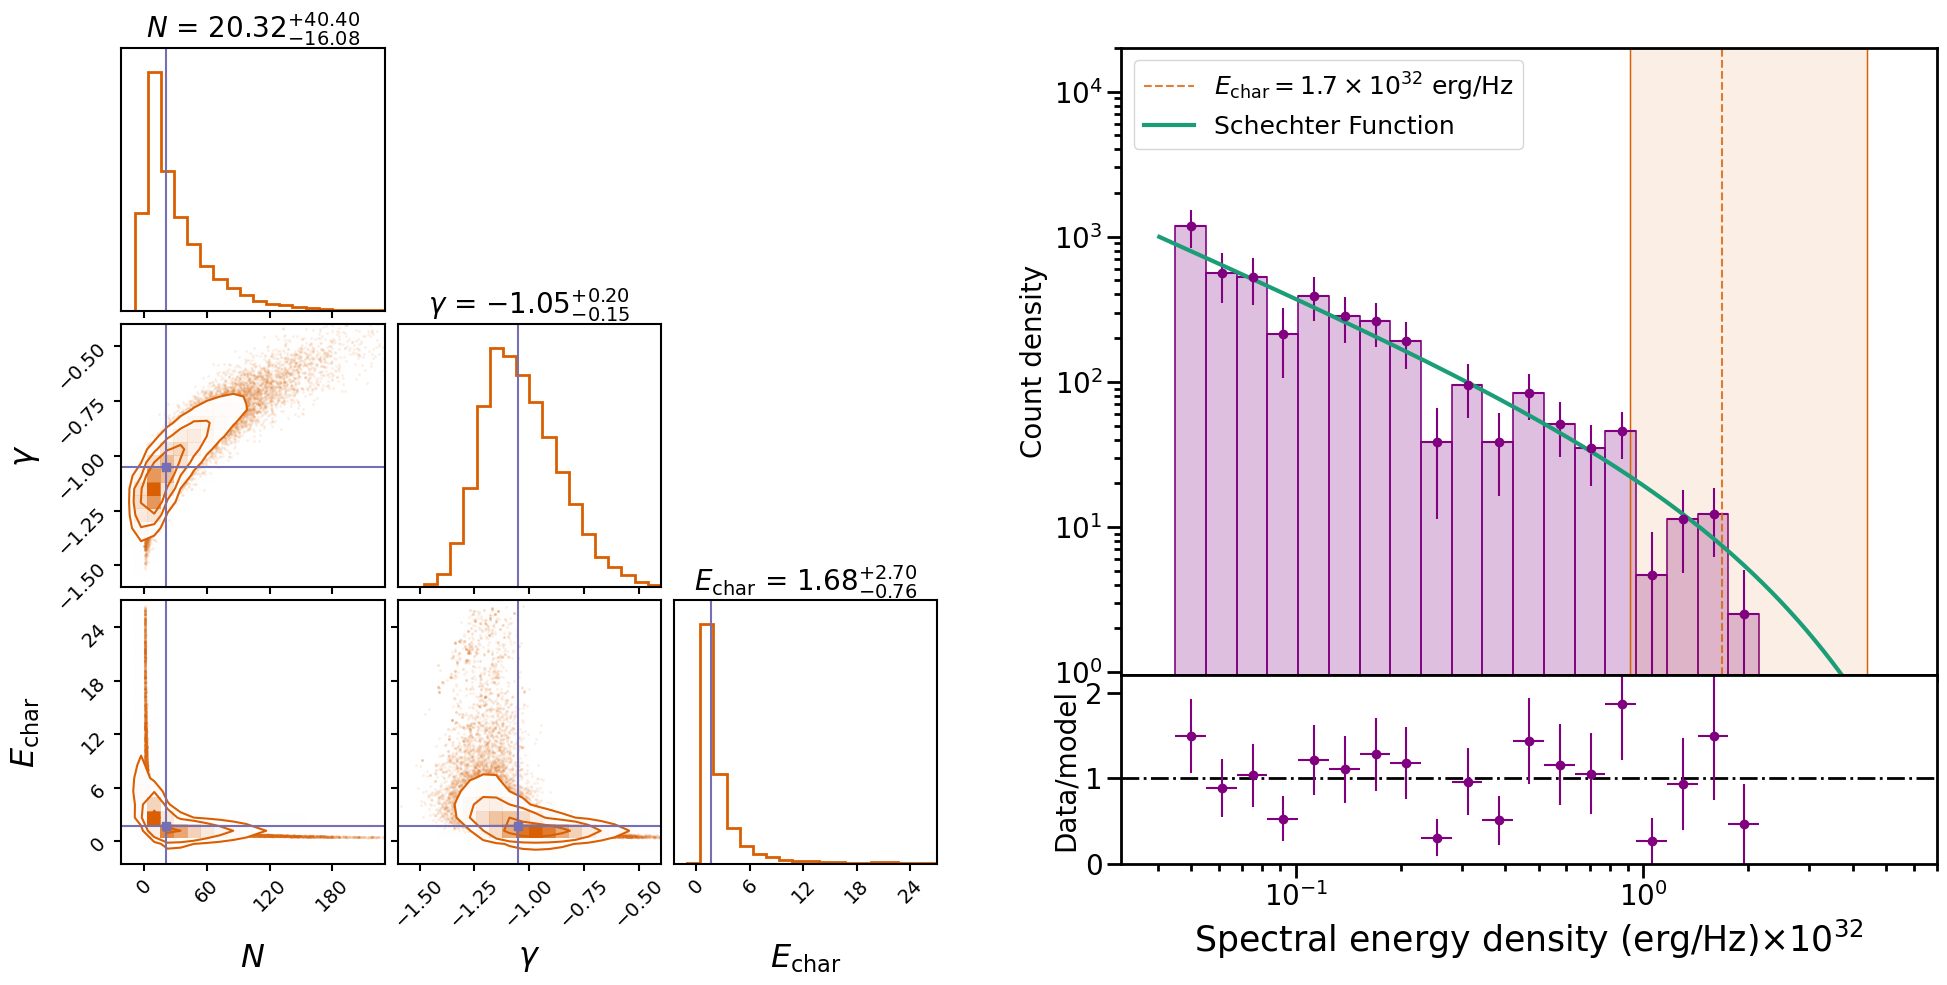

loading up the energies with len: 93 bursts for treshold_factor: 2.0
Median and 1-sigma errors
N = 40.133 -31.448/+ 66.652
Gamma = -0.902 -0.236/+ 0.282
E_cut = 1.188 -0.495/+ 1.706
0.4946855721476202 1.7056305331184352
[40.132803763220664, -0.9023671614013398, 1.1875612186899331]
chi2: 5.99 and redchi2 0.50


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_2.0


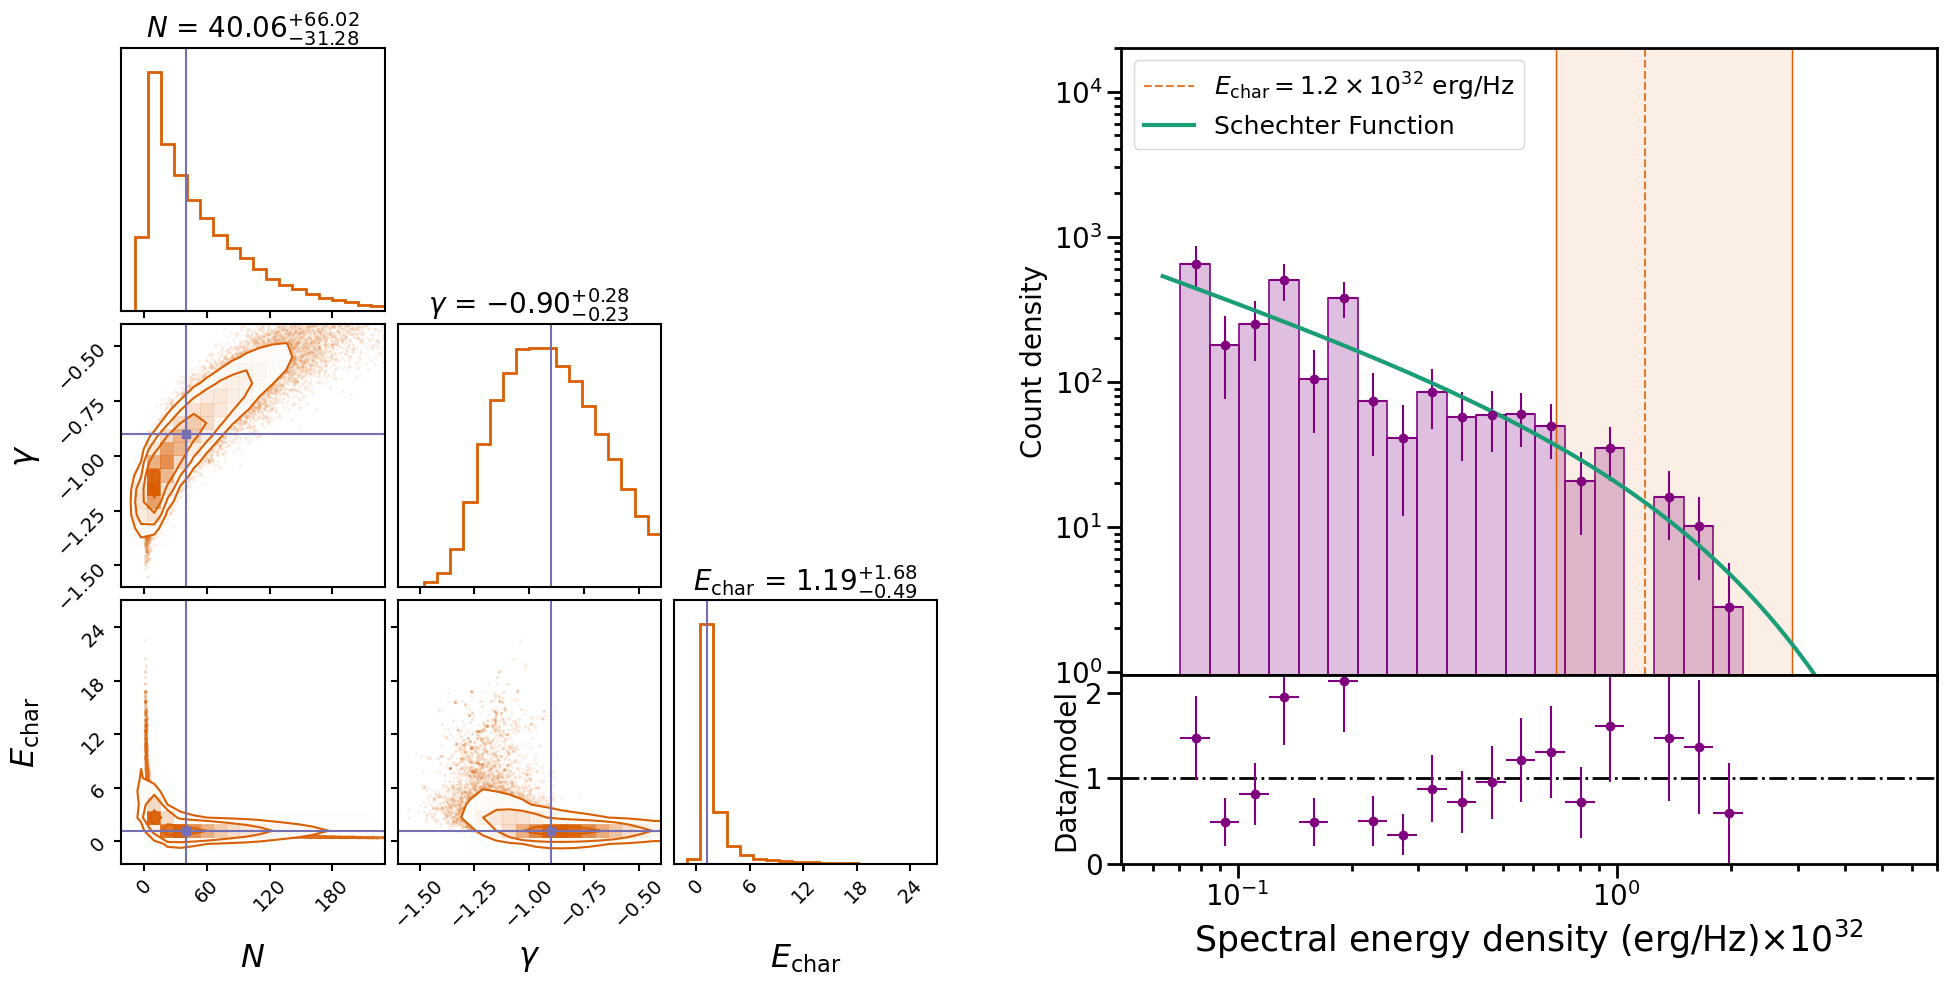

loading up the energies with len: 85 bursts for treshold_factor: 2.5
Median and 1-sigma errors
N = 32.297 -27.321/+ 66.753
Gamma = -0.931 -0.243/+ 0.314
E_cut = 1.332 -0.616/+ 2.728
0.6157112690941234 2.7276769356462123
[32.29677051508435, -0.9311429490952132, 1.3324942612884585]
chi2: 7.64 and redchi2 0.76


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_2.5


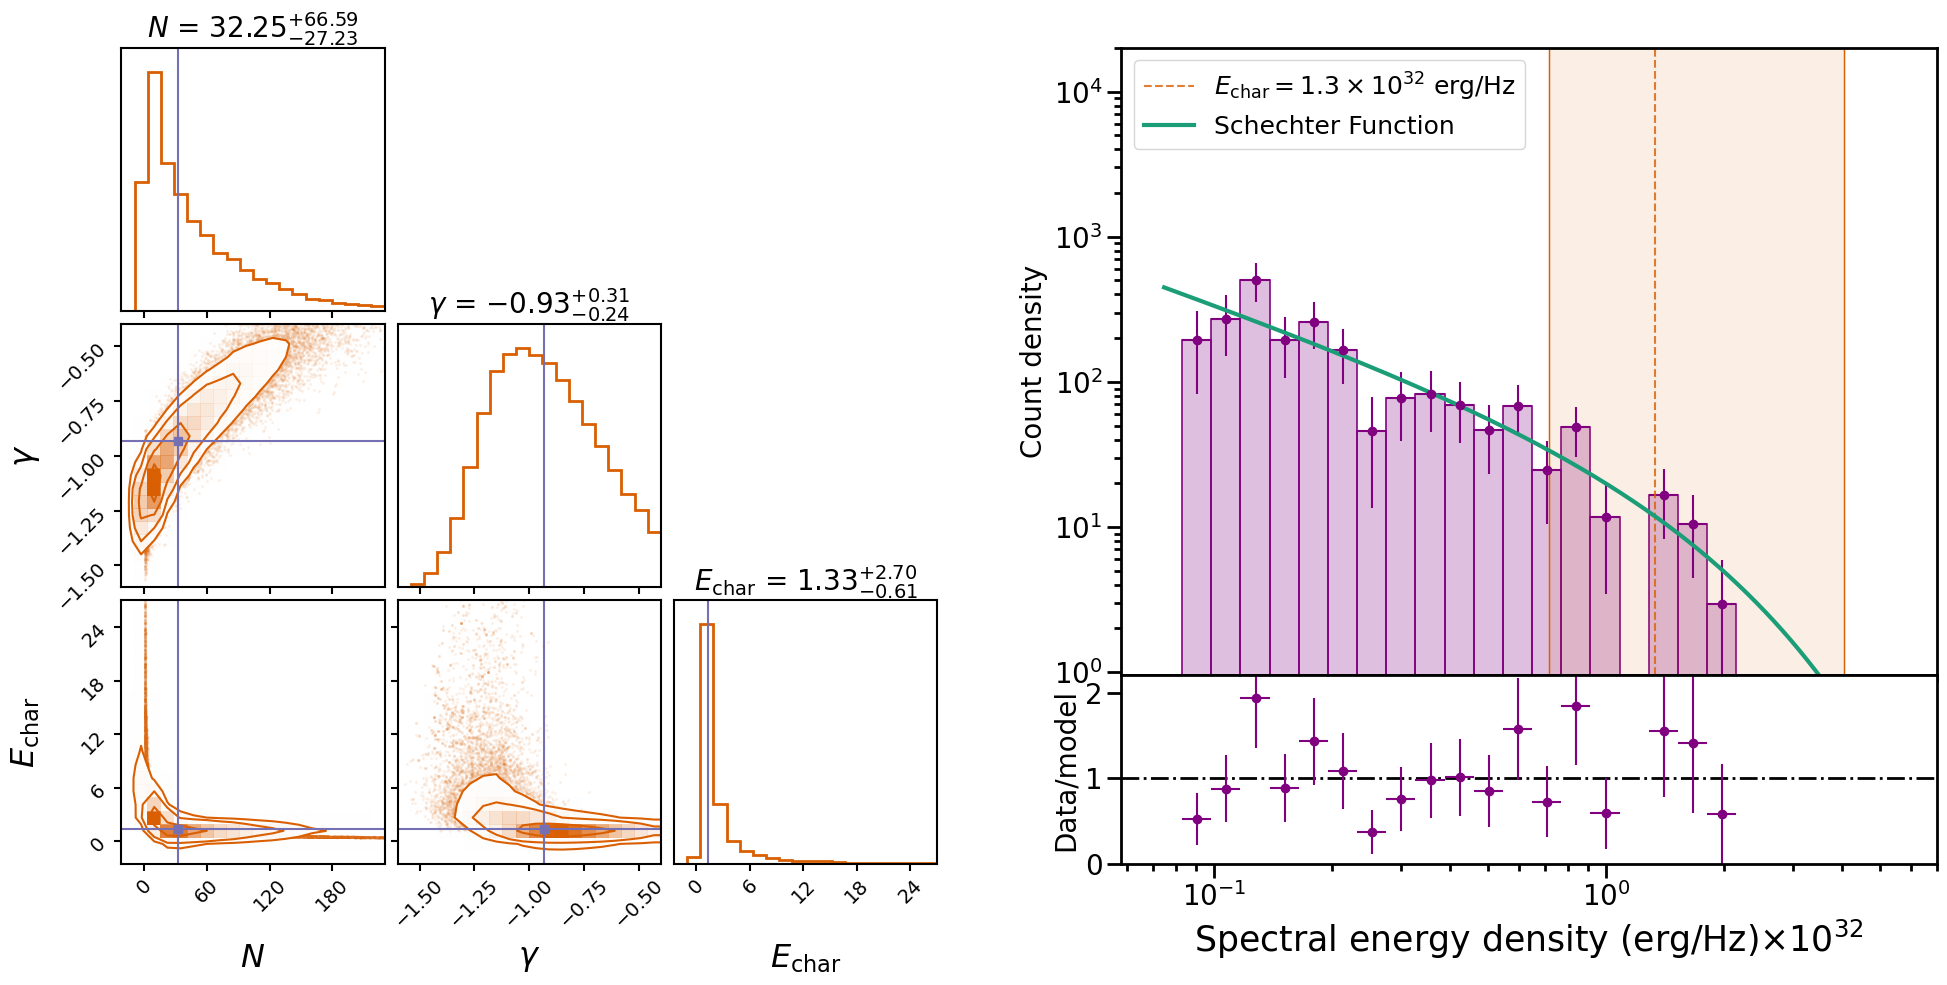

loading up the energies with len: 82 bursts for treshold_factor: 3.0
Median and 1-sigma errors
N = 15.905 -14.121/+ 47.816
Gamma = -1.110 -0.215/+ 0.296
E_cut = 1.895 -0.994/+ 5.117
0.9941036741073923 5.116814324636672
[15.905174281555906, -1.1104184448683017, 1.894773403683966]
chi2: 12.50 and redchi2 1.25


,threshold_jy_ms,threshold_erg_hz,treshold_factor,N_bursts,N_wb,N_stk,N_tr,N_nc,N_ata,N_fs,energy_arr_erg_hz_name,base_name,emcee_name,chi2,redchi2
0,16.103865,2.181250e+30,0.660,146,25,68,4,13,32,4,output_treshold_0.66_energies.txt,output_treshold_0.66,emcee_output_treshold_0.66_10000steps.h5,13.514291,1.126191
1,23.814200,3.225606e+30,0.976,130,23,64,2,9,30,2,output_treshold_0.976_energies.txt,output_treshold_0.976,emcee_output_treshold_0.976_10000steps.h5,10.252687,0.854391
2,24.399795,3.304924e+30,1.000,125,22,62,2,8,29,2,output_treshold_1.0_energies.txt,output_treshold_1.0,emcee_output_treshold_1.0_10000steps.h5,9.340697,0.778391
3,32.451727,4.395549e+30,1.330,112,20,55,2,7,27,1,output_treshold_1.33_energies.txt,output_treshold_1.33,emcee_output_treshold_1.33_10000steps.h5,7.966998,0.663916
4,48.799590,6.609848e+30,2.000,93,12,47,1,7,26,0,output_treshold_2.0_energies.txt,output_treshold_2.0,emcee_output_treshold_2.0_10000steps.h5,5.988598,0.499050
5,60.999488,8.262310e+30,2.500,85,11,45,1,6,22,0,output_treshold_2.5_energies.txt,output_treshold_2.5,emcee_output_treshold_2.5_10000steps.h5,7.640775,0.764078
6,73.199385,9.914772e+30,3.000,82,10,44,1,6,21,0,output_treshold_3.0_energies.txt,output_treshold_3.0,emcee_output_treshold_3.0_10000steps.h5,12.499546,1.249955


MCMC_plot_output_treshold_3.0


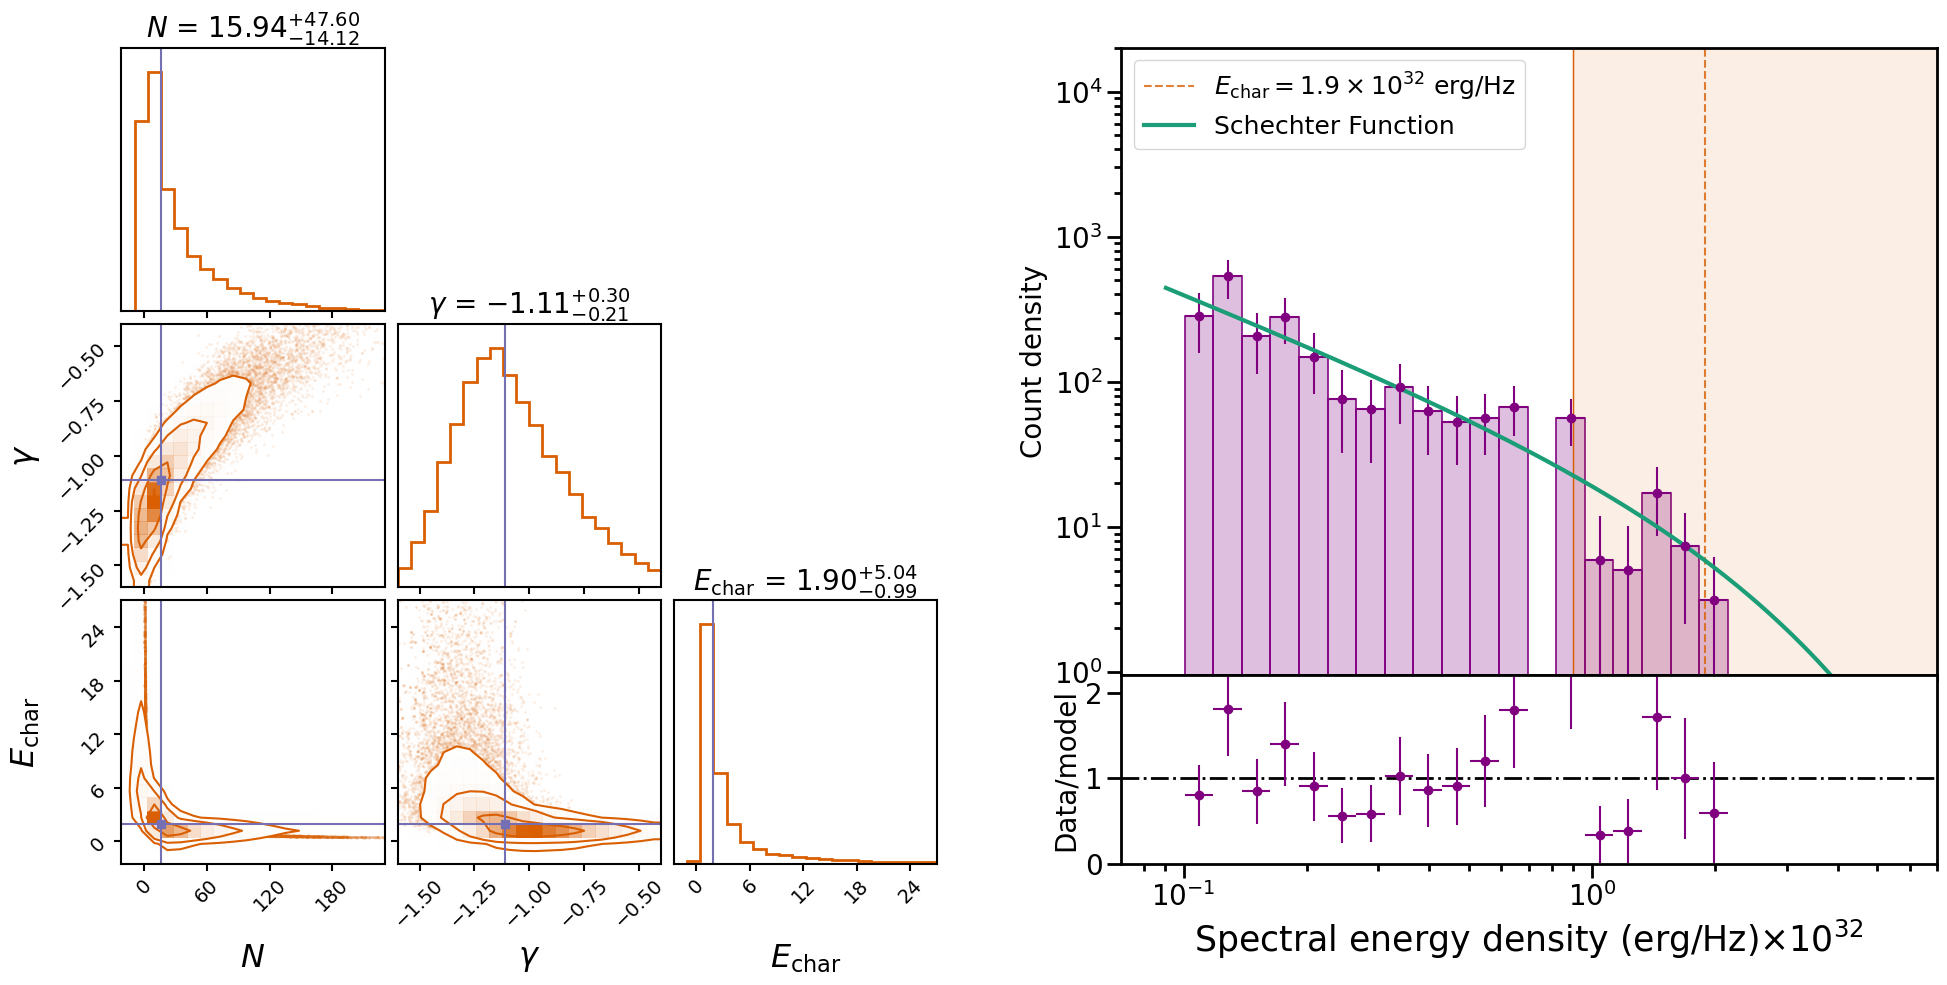

In [92]:
# #Running the MCMC analysis 5 times for different thresholds. 
# #Here factor 1.826 which is the golden egg
def draw_loop():

    factors = [0.66,0.976,1.0,1.33,2.0,2.5,3.0]
    
    for fac in factors:
        draw_figure(treshold_factor=fac)

    return
    
draw_loop()

In [129]:
def emcee_plots(filename_emcee):

    """
    filename_emcee = filename given to the h5 file


    part 2
    - Place figures next to eachother based on the best fit values
    
    In order to run this function you need to have run the previous function, which is the emcee itself.
    The flat_samples are taken from sampler.get_chain and 
    """    
    # sampler_result = np.load(f"{save_name}.npy")
    sampler = emcee.backends.HDFBackend(filename_emcee)
    
    flat_samples_full = sampler.get_chain(discard=100, flat=True)
    print("Median and 1-sigma errors")
    #Changed this to hardcoded, since we won't change the function anymore
    ndim=3

    med_values = []
    for i in range(ndim):
        
        mcmc = np.percentile(flat_samples_full[:, i], [15.85, 50, 84.15])
        q = np.diff(mcmc)
        txt = "{3} = {0:.3f} -{1:.3f}/+ {2:.3f}" # This formatting rounds to 3 decimal places.
        txt = txt.format(mcmc[1], q[0], q[1], ['N','Gamma','E_cut'][i])
        print(txt)
        med_values.append(mcmc[1])
    
    labels_list = [r'$N$',r'$\gamma$',r'$E_{\rm cut}$'] # labels for our plots
   
    flat_samples = sampler.get_chain(discard=100, thin=30, flat=True) 

    fig_corn = corner.corner(flat_samples, labels=labels_list, smooth=0.5, \
                        max_n_ticks=5, show_titles=True, color="#d95f02",\
                        fill_contours=False, title_kwargs={"fontsize": 20},linewidth=20, truths=med_values, truth_color="#7570b3",\
                        plot_datapoints=True, range=[(-20, 240), (-1.5, -0.5), (-2.0, 29)],\
                        hist_kwargs={"linewidth":2}, label_kwargs={"fontsize": 23})

    #Hacky tacky method to get label ticks larger size -- from: https://github.com/dfm/corner.py/issues/102
    for ax in fig_corn.get_axes():
        ax.tick_params(axis='both', labelsize=14)

        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(1.5)

            ax.tick_params(axis='y', which='major', direction='out', length=5, width=1.5)
            ax.tick_params(axis='x', which='major', direction='out', length=5, width=1.5)
    
    # save_name="MCMC_corner_plot"
    # plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    # plt.savefig(f"../plots/{save_name}.png", \
    #         bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()
        
    return flat_samples

Median and 1-sigma errors
N = 16.646 -13.093/+ 29.005
Gamma = -1.084 -0.111/+ 0.131
E_cut = 1.866 -0.821/+ 3.148


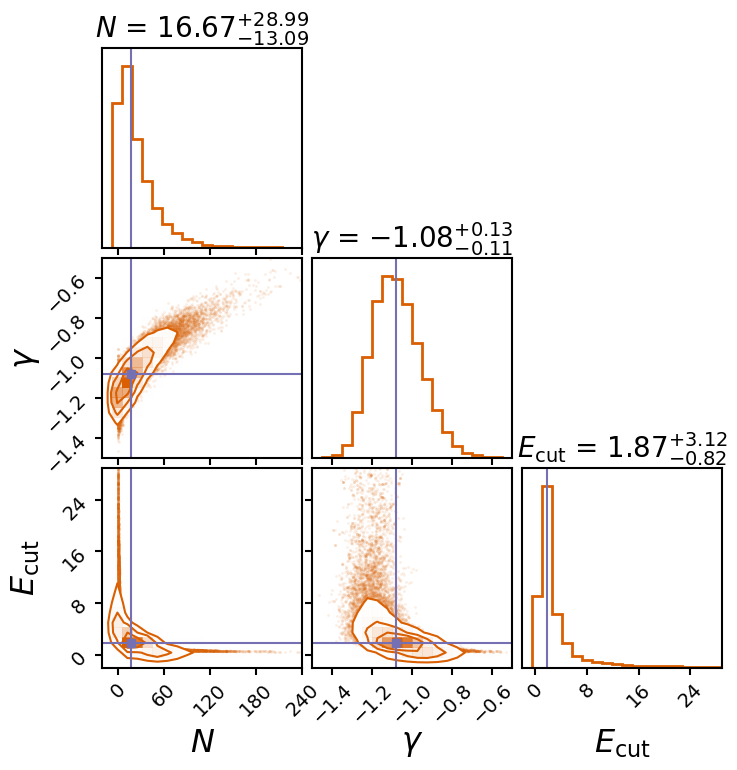

In [114]:
flat_samples = emcee_plots(filename_emcee)

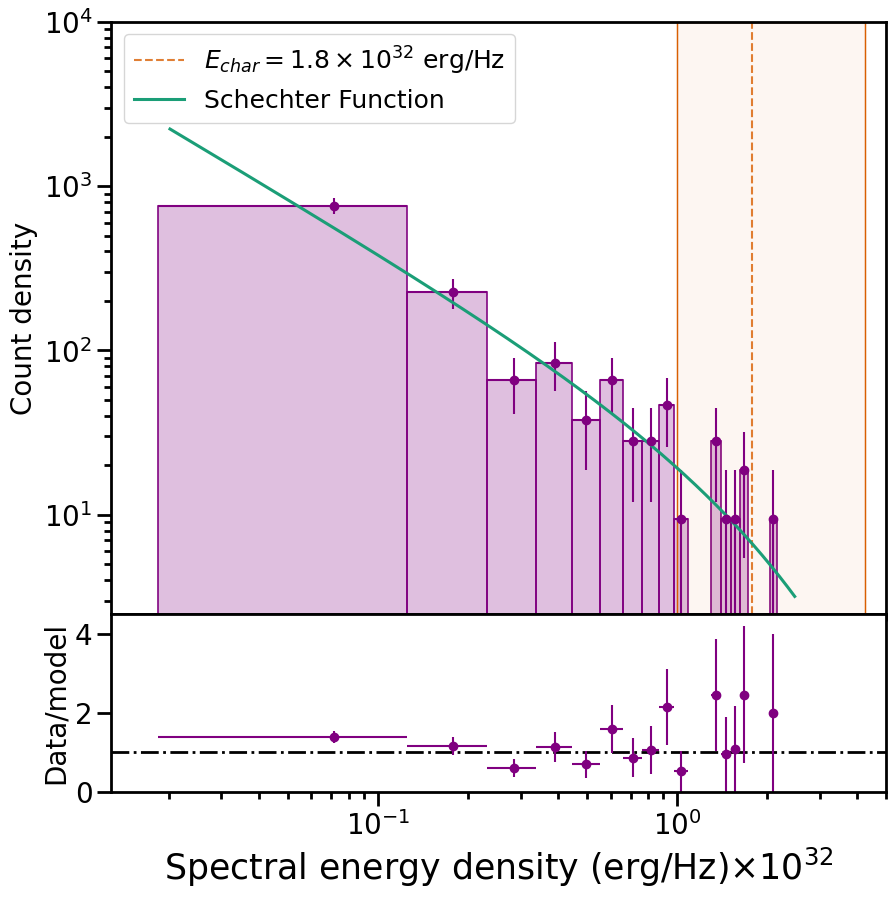

In [86]:
def formatter(x, pos):
    del pos
    return str(f"{x*1e32}")

def plot(energies_global):
    
    #Best fit parameters on the model
    N=18.118
    gamma=-1.076
    ecut=1.785  

    energies = energies_global/1e32
    
    fig, (ax1, ax2) = plt.subplots(2,1, figsize=(10,10),sharex=True,gridspec_kw={'height_ratios':[2,0.6]})
    fig.subplots_adjust(hspace=0)
    
    counts, edges = np.histogram(energies, bins=20, density=False)
    energies = (edges[1:]+edges[:-1])/2

    bwidths = np.diff(edges) # calculates the width of each bin
    cdens = counts/bwidths # determines the count densities
    cdens_err = np.sqrt(counts)/bwidths # calculate the errors: remember the error is based on the counts, 

    ax1.bar(energies, cdens, width=bwidths, align='center',edgecolor = 'purple', alpha=0.25,color='purple', linewidth=1.1)
    ax1.bar(energies, cdens, width=bwidths, align='center',edgecolor = 'purple', alpha=1.0,color='None', linewidth=1.1)
    ax1.errorbar(energies, cdens, xerr=bwidths/2., yerr=cdens_err, fmt='o', color="purple")
    
    ax1.axvline(ecut, color='#d95f02', alpha=0.8, linestyle="--", \
                label=fr'$E_{{char}}={ecut:.1f}\times 10^{{32}}$ erg/Hz')
    neg_error = 0.783
    pos_error = 2.445
    ax1.axvspan(ecut - neg_error, ecut + pos_error, alpha=0.05, color='#d95f02')
    ax1.axvspan(ecut - neg_error, ecut + pos_error, alpha=1.0, color='None',ec='#d95f02', linestyle='-', linewidth=1.05)
    
    pars=[N, gamma, ecut]
    x_range = np.linspace(1.1*edges[0], edges[-1]*1.15, 800)
    y = func_schechter_emcee(x_range, [N, gamma, ecut])
    # y_p = func_powerlaw_emcee(x_range, [19.12,-1.09])
    
    ax1.plot(x_range,y, color='#1b9e77', label="Schechter Function", lw=2.2)
    ax1.set_xlim(0.7*edges[0], 5)
    ax1.set_ylim(2.5,10000)    

    ##Residuals
    y_model = func_schechter_emcee(energies, [N, gamma, ecut])
    ax2.set_ylim(0,4.5)
    ax2.axhline(1, linestyle="-.", color="black", lw=2)

    #Find out where the frac is zero
    ratio = cdens/y_model

    #Mask to delete the zero values in the plot
    mask = (ratio != 0)
    ax2.errorbar(energies[mask], ratio[mask], xerr=bwidths[mask]/2., yerr=cdens_err[mask]/y_model[mask], fmt='o', color='purple')
    
    for ax in [ax1,ax2]:
        for axis in ['top','bottom','left','right']:
            ax.spines[axis].set_linewidth(2)

            ax.tick_params(axis='y', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='y', which='minor', direction='out', length=5, width=2)
            ax.tick_params(axis='x', which='major', direction='out', length=10, width=2)
            ax.tick_params(axis='x', which='minor', direction='out', length=5, width=2)
        
        ax.tick_params(axis='both', which='major', labelsize=20)

    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_ylabel(fr"Count density", fontsize=20)
    ax2.set_ylabel(fr"Data/model", fontsize=20)
    ax2.set_xlabel(fr"Spectral energy density (erg/Hz)$\times 10^{{32}}$", fontsize=25)    

    # offset = 10**32

    # ax1.set_xticks(energies,\
    #           [rf"$10^{{{energies}}}$" for energies in np.log10((energies * offset).astype(np.float64)).astype(np.int32)])

#     np.set_printoptions(suppress=True)
#     ticks = ax2.get_xticks()*10**32
#     ax2.set_xticklabels(ticks)
#     #ax2.xaxis.set_major_formatter(formatter)

    ax1.legend(loc='upper left', fontsize=18, markerscale=2)
    
    # save_name="schechter_model_fit"
    # plt.savefig(f"../plots/{save_name}.pdf", format = 'pdf', dpi=600, bbox_inches='tight')
    # plt.savefig(f"../plots/{save_name}.png", \
    #         bbox_inches='tight', facecolor='white', transparent=False, dpi=300)
    plt.show()
    
plot(energies_global)

In [21]:
# def func_schechter(x, params):
#     """
#     Schechter function as shown in Shin-2023, eq.2
#     x = energy-array
#     echar = characteristic cut-off energy
#     gamma = slope
#     scale = scaling factor
#     """
#     v = params.valuesdict()
#     return v['N']*(x**v['gamma'])*np.exp(-1*x/v['E_cut'])

In [22]:
# def func_powerlaw(x, params):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            parm - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     v = params.valuesdict()
#     return v['N'] * ((x)**v['gamma'])

In [24]:
# def func_schechter_s(x, params):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            parm - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     v = params.valuesdict()
#     return v['N'] *((x)**v['gamma']) * np.exp(-x/v['E_cut'])

In [25]:
# def func_schechter_emcee_s(x, pars):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     (N,gamma,E_cut) = pars
#     return N *((x)**gamma)*np.exp(-x/E_cut)

In [28]:
# def func_schechter_k(x, params):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            parm - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     v = params.valuesdict()
#     return (v['N']/v['E_cut']) *((x/v['E_cut'])**v['gamma']) * np.exp(-x/v['E_cut'])

In [29]:
# def func_schechter_emcee_k(x, pars):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     (N,gamma,E_cut) = pars
#     return (N/E_cut) *((x/E_cut)**gamma)*np.exp(-x/E_cut)

In [30]:
# def func_schechter2(x, params):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            parm - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     v = params.valuesdict()
#     return (1/v['E_cut']) * ((x/v['E_cut'])**v['gamma']) * np.exp(-x/v['E_cut'])

In [31]:
# def func_schechter_emcee2(x, pars):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     (gamma,E_cut) = pars
#     return (1/E_cut) * ((x/E_cut)**gamma)* np.exp(-x/E_cut)

In [23]:
# def func_powerlaw_emcee(x, pars):
#     '''Power-law function with an exponential cut-off.
#        Inputs:
#            x - input x value(s) (can be list or single value).
#            pars - parameters, list of PL normalisation (at x = 1) and power-law index.'''
#     (N,gamma) = pars
#     return N*((x)**gamma)

In [83]:
# save_name_r67, ndim_r67, nwalkers_r67, sampler_r67, result_r67 = run_emcee(energies=energies_global_r67, nbins=20, steps=1000)
# emcee_plots(save_name_r67, ndim_r67, nwalkers_r67, sampler_r67, result_r67)

In [98]:
# def plexp(x,alpha,xcut):
#     '''Power-law function with index alpha an exponential cut-off with scaling factor xcut'''
#     return (x**alpha)*np.exp(-x/xcut)

# def powinvcdf(prob,alpha,xmin,xmax):
#     '''Inverse cdf (i.e. point percent function) of a simple power-law with lower and upper bounds
#     at xmin and xmax respectively. Returns x value corresponding to given cdf probability prob.'''
#     if alpha != -1:
#         xval = (prob*(xmax**(alpha+1)-xmin**(alpha+1))+xmin**(alpha+1))**(1/(alpha+1))
#     else:
#         xval = x_min*(x_max/x_min)**prob
#     return xval

# def sample_plexp_plcdf(nsamp,xmin,xmax,alpha,xcut):
#     '''Accept-reject sampling of function f(x) which is a power-law with exponential cut-off. 
#     Trial x values are drawn from a power-law distribution bounded by xmin and xmax. 
#     Trial probabilities are drawn from U[0,1] and accepted if p<=f'(x)/f'(xmin) 
#     where f'(x) corresponds to the exponential function only and f'(xmin) should be the maximum
#     value of f'(x).'''
#     xvals = np.zeros(nsamp)
#     i = 0
#     ntry = 0
#     ymax = plexp(xmin,alpha,xcut)  # Requires alpha to be negative
#     while i < nsamp:
#         xtry = powinvcdf(sps.uniform.rvs(),alpha,xmin,xmax) # PL distributed x between xmin and xmax
#         ptry = sps.uniform.rvs() # uniform trial p value
#         if (ptry <= np.exp(-xtry/xcut)/np.exp(-xmin/xcut)): # condition to accept
#             xvals[i] = xtry
#             i = i+1
#         ntry = ntry+1            
#     return xvals, ntry

In [97]:
# def pl_inv_cdf(u, x_min, ind):
#     return x_min * ((1-u)**(1/(1-ind)))

# def inv_trans_samp(N, func, *args):
#     """Generate N samples based on the given inverse CDF (func) and corresponding arguments"""
#     u = np.random.rand(N)
#     x = func(u, *args)
#     return x

In [95]:
# def pragya_distr(obs_energies):
    
#     N = 2000
#     low_lim = np.min(obs_energies)
#     index = 1.53
#     e_cut = 1.6e32
#     # sampling function to generate events distributed as a power law 
#     energetics = inv_trans_samp(N, pl_inv_cdf, low_lim, index)
#     # sampling function to have a cutoff at higher energies
#     pdf = np.exp(-energetics/e_cut)
#     sim_prob = np.random.rand(len(energetics))
#     energetics = energetics[sim_prob<pdf]

#     bins = np.logspace(np.log10(np.min(energetics)), np.log10(np.max(energetics)), 20)
#     counts_norm, bins, _ = plt.hist(energetics, density = True, bins=bins, label="Data")
#     plt.gca().set_xscale("log")
#     plt.gca().set_yscale("log")

#     counts_norm, bins, _ = plt.hist(obs_energies, density = True, bins=bins, label="Observed", alpha=0.5, 
#                                             color = 'C3')
#     plt.legend(loc="best")
#     print(len(energetics))
    
#     return energetics
# energetics_sim = pragya_distr(obs_energies=energies_global)

In [96]:
# np.max(energetics_sim)

In [ ]:
#xvals, ntry = sample_plexp_plcdf(nsamp=500,xmin=3e30,xmax=10*1e32,alpha=-1.53,xcut=1e32)

In [ ]:
# bins = np.logspace(np.log10(np.min(xvals)), np.log10(np.max(xvals)), 20)
# bins_er = np.logspace(np.log10(np.min(energies_global)), np.log10(np.max(energies_global)), 20)

# plt.hist(xvals,bins)
# plt.hist(energies_global, bins_er)
# plt.xscale("log")

In [93]:
# save_name_tst, ndim_tst, nwalkers_tst, sampler_tst, result_tst = run_emcee(energetics_sim, nbins=20, steps=1000)

 36%|███████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                                                                                                                                  | 359/1000 [00:34<00:56, 11.43it/s]/tmp/ipykernel_3079464/619117448.py:7: RuntimeWarning: invalid value encountered in scalar power
  return (N/E_cut) *((x/E_cut)**gamma)*np.exp(-x/E_cut)
/tmp/ipykernel_3079464/1597742055.py:12: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  ymod[i], ymoderr = spint.quad(lambda x: model(x, params),xbins[i],xbins[i+1])
 37%|██████████████████████████████████████████████████████████████████████████████████████████████████████▌                                                                                                                                      

In [94]:
# emcee_plots(save_name_tst, ndim_tst, nwalkers_tst, sampler_tst, result_tst)